# Q-DecodeQEC: decoding real IBM repetition-code syndromes (M0 matching, M1 MLP, M2 MOR router) and a passive vs active memory circuit on real hardware

**Participant:** Kaustubh Ladda (GitHub: `kaustubhkladda`) | **Event:** Trinexis x IEEE, IBM Qiskit Fall Fest 2026 | **Domain:** Quantum Error Correction

## 00 Cover: the contract

**Task.** Given the 8 detector bits of one shot of a distance-3, three-round bit-flip repetition-code memory measured on `ibm_marrakesh`, predict whether the logical observable flipped (`observable_error`). Compare three mandatory decoders on identical shots and demonstrate a passive (BEFORE) versus an actively corrected (AFTER) memory circuit on a real IBM quantum computer.

**Data.** Only `data/` of the repository is used for training: `train_4000`, `internal_test_1000` (labelled), `final_test_inputs` (2,000 unlabelled shots from a later job). Nothing is simulated.

**Allowed compute.** Local CPU for pandas, scikit-learn, PyMatching, plotting and transpilation. Every quantum number comes from a real IBM backend job. No simulator of any kind appears in this notebook (a scan in section 01 enforces it).

**Method IDs.** M0 = PyMatching MWPM + no-flip and pattern-lookup controls. M1 = MLP. M2 = MOR router (difficulty classes, per-class routing, Platt calibration). Stretch methods S1 and S2 (quantum kernel SVM, QAOA + VQC) are **NOT_ATTEMPTED** (they are optional and the QPU budget is reserved for Part A and retries).

**Status flags used below.** `OK`, `BLOCKED_IBM_ACCESS`, `BUDGET_EXHAUSTED`, `NOT_ATTEMPTED`, `NOT_STATISTICALLY_RESOLVABLE`, `CACHED_REAL_QPU`.

**Reading guide.** Every code cell has a six-field Markdown cell above it. Each code cell finishes by printing an `INSIGHTS:` block that is built from the numbers it just computed, so the interpretation can never drift away from the output.

**Secrets.** Put your IBM credentials in environment variables or in a git-ignored `.env` file in the repository root (see section 01). They are never printed, never written to a file by this notebook, and a final scan checks that they do not appear anywhere in the repository folder.

## 01 Environment, configuration and secrets

### Config cell, versions, seeds, credentials loader
**Purpose:** Create one `CONFIG`, fix all seeds, print package versions against the tested versions, locate the repository and load credentials from the environment without printing them.

**Inputs:** Environment variables `QISKIT_IBM_TOKEN`, `QISKIT_IBM_INSTANCE`, `QISKIT_IBM_CHANNEL` (optional, defaults to `ibm_quantum_platform`), optionally a git-ignored `.env` file in the repository root or next to this notebook.

**Method:** A tiny parser reads `KEY=VALUE` lines of a `.env` file into `os.environ` only for keys that start with `QISKIT_IBM_` or `QDECODE_`, and only when the key is not already set. The values are never echoed.

**Expected output:** Versions table, the config dictionary (no secrets), the repository root and a boolean for each credential (present or not).

**Interpretation:** Matching versions make the run reproducible; different versions are allowed but must be stated, which the table does.

**Failure mode:** A missing `.env` is fine for the classical part; hardware sections then report `BLOCKED_IBM_ACCESS` instead of failing.

In [1]:
import os, sys, json, re, time, math, hashlib, platform, warnings, random, datetime as dt, itertools
from pathlib import Path
from copy import deepcopy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import scipy, sklearn, pymatching, qiskit, qiskit_ibm_runtime, joblib
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 2026
random.seed(SEED); np.random.seed(SEED)

SRC_DIR = Path.cwd().resolve()
def find_repo_root():
    for cand in [SRC_DIR, *SRC_DIR.parents]:
        if (cand / "data" / "train_4000.parquet").exists():
            return cand
    raise FileNotFoundError("Could not find data/train_4000.parquet above " + str(SRC_DIR) + ". Start Jupyter inside the submission src/ folder.")
REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
OUT_DIR = SRC_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
for d in (OUT_DIR, FIG_DIR, OUT_DIR / "frozen", OUT_DIR / "partA", OUT_DIR / "qpy"):
    d.mkdir(parents=True, exist_ok=True)

# ---- credentials: environment first, then a git-ignored .env (values are never printed) ----
def load_env_file(path):
    loaded = []
    if not path.exists():
        return loaded
    for line in path.read_text(encoding="utf-8", errors="ignore").splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        k, v = k.strip(), v.strip().strip('"').strip("'")
        if (k.startswith("QISKIT_IBM_") or k.startswith("QDECODE_")) and k not in os.environ and v:
            os.environ[k] = v
            loaded.append(k)
    return loaded
ENV_FILES_USED = {}
for cand in (REPO_ROOT / ".env", SRC_DIR / ".env"):
    got = load_env_file(cand)
    if got:
        ENV_FILES_USED[str(cand.relative_to(REPO_ROOT))] = got
os.environ.setdefault("QISKIT_IBM_CHANNEL", "ibm_quantum_platform")
SECRET_VALUES = [os.environ[k] for k in ("QISKIT_IBM_TOKEN", "QISKIT_IBM_INSTANCE") if os.environ.get(k)]
def redact(text):
    text = str(text)
    for s in SECRET_VALUES:
        text = text.replace(s, "[REDACTED]")
    return text

gi = REPO_ROOT / ".gitignore"
gi_lines = gi.read_text().splitlines() if gi.exists() else []
env_ignored = any(l.strip() in (".env", "*.env", ".env*") for l in gi_lines)

CONFIG = dict(
    seed=SEED,
    boot_single=1000, boot_paired=2000, cv_folds=5,
    matching_ratio_grid=[0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0],
    mlp_sizes=[(16,), (32, 32), (64, 64), (128, 64, 32)],
    mlp_alphas=[1e-4, 1e-2],
    mlp_max_epochs=150, mlp_patience=15, mlp_batch=64, mlp_lr=1e-3,
    slices=dict(fit=0.6, val=0.2, route=0.2),
    difficulty=dict(trivial="w == 0", easy="w in {1, 2}", hard="w >= 3"),
    shots_partA=250, shots_calibration=100,
    qpu_budget_s=600, qpu_reserve_s=130, qpu_partA_cap_s=40, qpu_calibration_cap_s=30,
    transpile_optimization_level=1,
    submit_to_qpu=os.environ.get("QDECODE_SUBMIT", "1") == "1",
    backend_name=os.environ.get("QDECODE_BACKEND") or None,
    latency_single_shots=300, latency_batch_repeats=15,
)
(OUT_DIR / "config.json").write_text(json.dumps(CONFIG, indent=2, default=str))

tested = {"qiskit": "2.5.0", "qiskit_ibm_runtime": "0.48.0", "pymatching": "2.4.0", "pandas": "2.3.2", "numpy": "2.1.0",
          "scipy": "1.18.0", "sklearn": "1.7.1", "matplotlib": "3.10.6", "joblib": "1.5.3"}
mods = dict(qiskit=qiskit, qiskit_ibm_runtime=qiskit_ibm_runtime, pymatching=pymatching, pandas=pd, numpy=np, scipy=scipy,
            sklearn=sklearn, matplotlib=matplotlib, joblib=joblib)
ver = pd.DataFrame([(k, tested[k], mods[k].__version__, "same" if mods[k].__version__ == tested[k] else "DIFFERENT") for k in tested],
                   columns=["package", "tested", "installed", "status"])
print("Python", platform.python_version(), "|", platform.platform())
display(ver)
print("Repository root :", REPO_ROOT)
print("Notebook folder :", SRC_DIR)
print("Outputs folder  :", OUT_DIR)
print("Credentials present -> token:", bool(os.environ.get("QISKIT_IBM_TOKEN")), "| instance CRN:", bool(os.environ.get("QISKIT_IBM_INSTANCE")),
      "| channel:", os.environ.get("QISKIT_IBM_CHANNEL"))
print(".env keys loaded from files:", {k: len(v) for k, v in ENV_FILES_USED.items()} or "none", "| .gitignore ignores .env:", env_ignored)
print("CONFIG saved to outputs/config.json")
n_diff = int((ver.status == "DIFFERENT").sum())
print("\nINSIGHTS:", f"{n_diff} package(s) differ from the tested versions (allowed if stated). Seed {SEED} drives every split, bootstrap and optimiser.",
      "Credentials were found." if SECRET_VALUES else "No IBM credentials found, so hardware sections will report BLOCKED_IBM_ACCESS.",
      "" if env_ignored else "WARNING: .gitignore does not list .env, add it before committing.")

Python 3.12.10 | Windows-11-10.0.26300-SP0


,package,tested,installed,status
0,qiskit,2.5.0,2.5.0,same
1,qiskit_ibm_runtime,0.48.0,0.48.0,same
2,pymatching,2.4.0,2.4.0,same
3,pandas,2.3.2,2.3.2,same
4,numpy,2.1.0,2.1.0,same
5,scipy,1.18.0,1.18.0,same
6,sklearn,1.7.1,1.7.1,same
7,matplotlib,3.10.6,3.10.6,same
8,joblib,1.5.3,1.5.3,same


Repository root : E:\Quantum NEW\Programming\Quantum QEC
Notebook folder : E:\Quantum NEW\Programming\Quantum QEC\submissions\kaustubhkladda_Kaustubh_Ladda_FALL_FEST_2026\src
Outputs folder  : E:\Quantum NEW\Programming\Quantum QEC\submissions\kaustubhkladda_Kaustubh_Ladda_FALL_FEST_2026\src\outputs
Credentials present -> token: True | instance CRN: True | channel: ibm_quantum_platform
.env keys loaded from files: {'.env': 3} | .gitignore ignores .env: True
CONFIG saved to outputs/config.json

INSIGHTS: 0 package(s) differ from the tested versions (allowed if stated). Seed 2026 drives every split, bootstrap and optimiser. Credentials were found. 


### No-simulator scan of every notebook and source cell
**Purpose:** Prove that no quantum simulator, fake backend or statevector tool is used anywhere in the code of this submission.

**Inputs:** This notebook file on disk (`main.ipynb`) and every `.py` file in the same folder.

**Method:** Regular expressions for the forbidden symbols are assembled from fragments so that this scanning cell does not match itself. Only **code** cells are scanned.

**Expected output:** A table of patterns with the number of hits, and a pass/fail line.

**Interpretation:** Zero hits means the code never references a local simulator, so every quantum number must have come from a backend job.

**Failure mode:** If the notebook has not been saved yet the on-disk copy can be stale; the scan is repeated in the final section after saving.

In [2]:
import nbformat
FORBIDDEN = {
    "local simulator package": "qiskit" + "_" + "aer",
    "local simulator symbol": r"\b" + "A" + "er" + r"\b",
    "local simulator class": "A" + "er" + "Simulator",
    "statevector tools": "State" + "vector",
    "density matrix": "Density" + "Matrix",
    "basic simulator": "Basic" + "Simulator",
    "fake backends": "Fa" + r"ke\w*" + "Backend",
    "fake provider": "Fa" + "ke" + "Provider",
    "generic backend": "Generic" + "Backend",
    "classical eigensolver stand-in": "NumPy" + "MinimumEigensolver",
}
def scan_sources():
    texts = {}
    nb_path = SRC_DIR / "main.ipynb"
    nbs = [nb_path] if nb_path.exists() else sorted(SRC_DIR.glob("*.ipynb"))
    for p in nbs:
        nb = nbformat.read(p, as_version=4)
        texts[p.name] = "\n".join(c.source for c in nb.cells if c.cell_type == "code")
    for p in sorted(SRC_DIR.glob("*.py")):
        texts[p.name] = p.read_text(errors="ignore")
    rows = []
    for name, pat in FORBIDDEN.items():
        hits = sum(len(re.findall(pat, t)) for t in texts.values())
        rows.append((name, hits))
    return texts, pd.DataFrame(rows, columns=["forbidden pattern", "hits"])
scanned, scan_df = scan_sources()
display(scan_df)
print("Files scanned:", list(scanned) or "none found (notebook not saved yet)")
SIM_SCAN_PASS = bool(scan_df.hits.sum() == 0)
print("SIMULATOR SCAN:", "PASS" if SIM_SCAN_PASS else "FAIL")
assert SIM_SCAN_PASS, "Remove the flagged simulator symbols before continuing."
print("\nINSIGHTS:", f"{len(scanned)} file(s) scanned against {len(FORBIDDEN)} forbidden patterns with {int(scan_df.hits.sum())} hits.")

,forbidden pattern,hits
0,local simulator package,0
1,local simulator symbol,0
2,local simulator class,0
3,statevector tools,0
4,density matrix,0
5,basic simulator,0
6,fake backends,0
7,fake provider,0
8,generic backend,0
9,classical eigensolver stand-in,0


Files scanned: ['main.ipynb']
SIMULATOR SCAN: PASS

INSIGHTS: 1 file(s) scanned against 10 forbidden patterns with 0 hits.


## 02 Data integrity

### Verify SHA-256 checksums of every file in `data/`
**Purpose:** Make sure the files used are exactly the organisers' files and log their hashes.

**Inputs:** `data/SHA256SUMS.txt` (hash, then path relative to `data/`).

**Method:** For each listed file compute $\mathrm{SHA256}(\text{bytes})$ and compare with the listed hash.

**Expected output:** A table with one row per file: expected hash, computed hash, status.

**Interpretation:** All rows `OK` means the data are untouched. The hashes are stored in the freeze manifest later.

**Failure mode:** A mismatch (for example an editor that rewrote a file or Git changing line endings of a text file) stops the notebook so that nothing is trained on altered data.

In [3]:

from pathlib import Path
import hashlib
import re

checksum_file = DATA_DIR / "SHA256SUMS.txt"

for line in checksum_file.read_text(encoding="utf-8").splitlines():
    m = re.match(r"^([0-9a-fA-F]{64})\s+\*?(.+)$", line.strip())
    if not m:
        continue

    expected, rel = m.group(1).lower(), m.group(2).strip()
    path = DATA_DIR / rel

    if not path.exists():
        print("MISSING:", rel)
        continue

    actual = hashlib.sha256(path.read_bytes()).hexdigest()

    if actual != expected:
        print(f"\nMISMATCH: {rel}")
        print("Expected:", expected)
        print("Actual:  ", actual)
        print("Size:    ", path.stat().st_size, "bytes")



MISMATCH: dataset_card.json
Expected: f1f13a49a161e474225846f524e58714401e3d45b039fe2d447bf452c4ca5ff5
Actual:   6a79e75fd5173877cc796fde15f4cae37ac45e3c0b282b443f7e2ff61e8a3db1
Size:     839 bytes

MISMATCH: raw/syndromes_d3_r3_v1/ibm_result_verification.json
Expected: a15866fb0309a216ed9bf9b1eba3792ac6a9e24e3a5367549307d0f3da389577
Actual:   1ede5d56e38e40a6131d51272acff3796c8a2d59651d3c585fe1e3d9839f263e
Size:     554 bytes

MISMATCH: raw/syndromes_d3_r3_v1/manifest.json
Expected: d0c8052620457305a8fda35ada504feaec516b6410c7921ab210ca067efa6870
Actual:   b3d8859245ba9f502605000acbc0d530e4e4fdab3d2098a2ae5011ee8578b60d
Size:     10158 bytes


In [4]:

import json

files_to_inspect = [
    DATA_DIR / "dataset_card.json",
    DATA_DIR / "raw/syndromes_d3_r3_v1/ibm_result_verification.json",
    DATA_DIR / "raw/syndromes_d3_r3_v1/manifest.json",
]

for path in files_to_inspect:
    print(f"\n{'=' * 70}\nFILE: {path.relative_to(DATA_DIR)}")
    try:
        content = json.loads(path.read_text(encoding="utf-8"))
        print(json.dumps(content, indent=2, ensure_ascii=False)[:6000])
    except Exception as e:
        print("Could not parse JSON:", e)



FILE: dataset_card.json
{
  "backend": "ibm_marrakesh",
  "circuits": [
    "rep_d3_r3_b0_passive_natural",
    "rep_d3_r3_b1_passive_natural",
    "rep_d3_r3_b0_passive_xq0_after0",
    "rep_d3_r3_b0_passive_xq1_after0",
    "rep_d3_r3_b0_passive_xq2_after0",
    "rep_d3_r3_b0_passive_xq0_after1",
    "rep_d3_r3_b0_passive_xq1_after1",
    "rep_d3_r3_b0_passive_xq2_after1"
  ],
  "completed_at_utc": "2026-10-20T17:32:04.729349+00:00",
  "job_id": "dbbq3agc77vs7384te2g",
  "layout": [
    110,
    111,
    98,
    91,
    92
  ],
  "rows": {
    "full": 5000,
    "test": 1000,
    "train": 4000
  },
  "shots_per_circuit": 625,
  "simulated_data": false,
  "source": "IBM Quantum physical backend",
  "split": "stratified by circuit_name",
  "split_seed": 20261020,
  "submitted_at_utc": "2026-10-20T17:15:23.048113+00:00"
}

FILE: raw\syndromes_d3_r3_v1\ibm_result_verification.json
{
  "backend": "ibm_marrakesh",
  "checked_at_utc": "2026-10-20T18:14:08.296767+00:00",
  "job_id": "dbbq3ag

In [5]:

import hashlib
import json

files = [
    DATA_DIR / "dataset_card.json",
    DATA_DIR / "raw/syndromes_d3_r3_v1/ibm_result_verification.json",
    DATA_DIR / "raw/syndromes_d3_r3_v1/manifest.json",
]

for path in files:
    raw = path.read_bytes()
    parsed = json.loads(raw.decode("utf-8"))
    normalized = json.dumps(
        parsed, indent=2, ensure_ascii=False
    ).encode("utf-8")

    print(f"\n{path.relative_to(DATA_DIR)}")
    print("Original SHA-256: ", hashlib.sha256(raw).hexdigest())
    print("Normalized SHA-256:", hashlib.sha256(normalized).hexdigest())
    print("Original bytes:    ", len(raw))
    print("Normalized bytes:  ", len(normalized))



dataset_card.json
Original SHA-256:  6a79e75fd5173877cc796fde15f4cae37ac45e3c0b282b443f7e2ff61e8a3db1
Normalized SHA-256: f1f13a49a161e474225846f524e58714401e3d45b039fe2d447bf452c4ca5ff5
Original bytes:     839
Normalized bytes:   807

raw\syndromes_d3_r3_v1\ibm_result_verification.json
Original SHA-256:  1ede5d56e38e40a6131d51272acff3796c8a2d59651d3c585fe1e3d9839f263e
Normalized SHA-256: a15866fb0309a216ed9bf9b1eba3792ac6a9e24e3a5367549307d0f3da389577
Original bytes:     554
Normalized bytes:   539

raw\syndromes_d3_r3_v1\manifest.json
Original SHA-256:  b3d8859245ba9f502605000acbc0d530e4e4fdab3d2098a2ae5011ee8578b60d
Normalized SHA-256: d0c8052620457305a8fda35ada504feaec516b6410c7921ab210ca067efa6870
Original bytes:     10158
Normalized bytes:   9793


In [6]:

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

rows = []

for line in (DATA_DIR / "SHA256SUMS.txt").read_text().splitlines():
    m = re.match(r"^([0-9a-fA-F]{64})\s+\*?(.+)$", line.strip())
    if not m:
        continue

    expected, rel = m.group(1).lower(), m.group(2).strip().replace("\\", "/")
    p = DATA_DIR / rel

    got = None
    method = "missing"

    if p.exists():
        raw = p.read_bytes()
        got = sha256_bytes(raw)
        method = "raw"

        if got != expected and p.suffix.lower() == ".json":
            try:
                obj = json.loads(raw.decode("utf-8"))
                normalized = json.dumps(
                    obj, indent=2, ensure_ascii=False
                ).encode("utf-8")
                normalized_hash = sha256_bytes(normalized)

                if normalized_hash == expected:
                    got = normalized_hash
                    method = "normalized-json"
            except (ValueError, UnicodeDecodeError):
                pass

    rows.append({
        "file": rel,
        "expected": expected[:16] + "...",
        "computed": got[:16] + "..." if got else None,
        "method": method,
        "status": "OK" if got == expected else (
            "MISSING" if not p.exists() else "MISMATCH"
        ),
        "_full": got,
    })

integrity = pd.DataFrame(rows)
display(integrity.drop(columns="_full"))

DATA_HASHES = {
    r["file"]: r["_full"]
    for r in rows
    if r["status"] == "OK"
}

assert (integrity.status == "OK").all(), (
    "Checksum problem: "
    + str(integrity[integrity.status != "OK"].file.tolist())
)

print(
    f"\nINSIGHTS: {len(integrity)} files verified. "
    "JSON files were normalized for checksum comparison where needed."
)


,file,expected,computed,method,status
0,dataset_card.json,f1f13a49a161e474...,f1f13a49a161e474...,normalized-json,OK
1,final_test_inputs.parquet,99e219cc34f74843...,99e219cc34f74843...,raw,OK
2,internal_test_1000.parquet,02c61b3e5d9cd71f...,02c61b3e5d9cd71f...,raw,OK
3,raw/syndromes_d3_r3_v1/ibm_result_verification...,a15866fb0309a216...,a15866fb0309a216...,normalized-json,OK
4,raw/syndromes_d3_r3_v1/manifest.json,d0c8052620457305...,d0c8052620457305...,normalized-json,OK
5,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_na...,2f58439ff51c82d2...,2f58439ff51c82d2...,raw,OK
6,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_na...,01c18f60551cc852...,01c18f60551cc852...,raw,OK
7,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_xq...,ee478715bd54c8e7...,ee478715bd54c8e7...,raw,OK
8,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_xq...,df711e5ba62eaa11...,df711e5ba62eaa11...,raw,OK
9,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_xq...,5bbfcc1b53e90e20...,5bbfcc1b53e90e20...,raw,OK



INSIGHTS: 22 files verified. JSON files were normalized for checksum comparison where needed.


In [7]:

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


rows = []

for line in (DATA_DIR / "SHA256SUMS.txt").read_text(
    encoding="utf-8"
).splitlines():
    m = re.match(r"^([0-9a-fA-F]{64})\s+\*?(.+)$", line.strip())
    if not m:
        continue

    expected = m.group(1).lower()
    rel = m.group(2).strip().replace("\\", "/")
    p = DATA_DIR / rel

    got = None
    method = "missing"

    if p.is_file():
        # First, verify the exact original file bytes.
        got = sha256_file(p)
        method = "raw"

        # If raw verification fails, try normalized JSON.
        if got != expected and p.suffix.lower() == ".json":
            try:
                obj = json.loads(p.read_text(encoding="utf-8"))
                normalized = json.dumps(
                    obj,
                    indent=2,
                    ensure_ascii=False
                ).encode("utf-8")

                normalized_hash = sha256_bytes(normalized)

                if normalized_hash == expected:
                    got = normalized_hash
                    method = "normalized-json"

            except (ValueError, UnicodeDecodeError):
                pass

    rows.append({
        "file": rel,
        "expected": expected[:16] + "...",
        "computed": got[:16] + "..." if got else None,
        "method": method,
        "status": (
            "OK" if got == expected
            else "MISSING" if not p.is_file()
            else "MISMATCH"
        ),
        "_full": got,
    })


integrity = pd.DataFrame(rows)

display(integrity.drop(columns="_full"))

# Preserve hashes for downstream notebook cells.
DATA_HASHES = {
    r["file"]: r["_full"]
    for r in rows
    if r["status"] == "OK"
}

# Fail if any file is missing or fails verification.
problems = integrity.loc[
    integrity["status"] != "OK", "file"
].tolist()

assert not problems, f"Checksum problem: {problems}"

raw_count = sum(r["method"] == "raw" for r in rows)
normalized_count = sum(
    r["method"] == "normalized-json" for r in rows
)

print(
    f"\nINSIGHTS: {len(rows)} files verified successfully: "
    f"{raw_count} raw-byte checks and "
    f"{normalized_count} normalized-JSON checks."
)

print(
    "Parquet files verified: "
    + ", ".join(
        r["file"] for r in rows
        if r["file"].endswith(".parquet")
    )
)


,file,expected,computed,method,status
0,dataset_card.json,f1f13a49a161e474...,f1f13a49a161e474...,normalized-json,OK
1,final_test_inputs.parquet,99e219cc34f74843...,99e219cc34f74843...,raw,OK
2,internal_test_1000.parquet,02c61b3e5d9cd71f...,02c61b3e5d9cd71f...,raw,OK
3,raw/syndromes_d3_r3_v1/ibm_result_verification...,a15866fb0309a216...,a15866fb0309a216...,normalized-json,OK
4,raw/syndromes_d3_r3_v1/manifest.json,d0c8052620457305...,d0c8052620457305...,normalized-json,OK
5,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_na...,2f58439ff51c82d2...,2f58439ff51c82d2...,raw,OK
6,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_na...,01c18f60551cc852...,01c18f60551cc852...,raw,OK
7,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_xq...,ee478715bd54c8e7...,ee478715bd54c8e7...,raw,OK
8,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_xq...,df711e5ba62eaa11...,df711e5ba62eaa11...,raw,OK
9,raw/syndromes_d3_r3_v1/rep_d3_r3_b0_passive_xq...,5bbfcc1b53e90e20...,5bbfcc1b53e90e20...,raw,OK



INSIGHTS: 22 files verified successfully: 19 raw-byte checks and 3 normalized-JSON checks.
Parquet files verified: final_test_inputs.parquet, internal_test_1000.parquet, train_4000.parquet


## 03 Schema, audit and detector-layout verification

### Load the three tables and audit the schema
**Purpose:** Check columns, types, nulls, bit ranges, list lengths and duplicate ids, then build the model arrays.

**Inputs:** `train_4000.parquet`, `internal_test_1000.parquet`, `final_test_inputs.parquet`.

**Method:** Lists such as `detectors` are stacked into integer matrices of shape (shots, 8) and (shots, 6). Every entry must be in $\{0,1\}$. The final-test table must contain only `record_id`, `syndrome`, `detectors`.

**Expected output:** Audit table (rows, nulls, ranges, lengths) and the shapes of the arrays used from now on.

**Interpretation:** A clean audit means the arrays can be trusted. The final-test file having no label columns is what keeps the final test leakage-safe.

**Failure mode:** A wrong list length or a value other than 0/1 would silently corrupt the matching graph indices, hence the hard asserts.

In [8]:
def stack(df, col):
    return np.vstack([np.asarray(v) for v in df[col]]).astype(np.int8)

tr = pd.read_parquet(DATA_DIR / "train_4000.parquet")
te = pd.read_parquet(DATA_DIR / "internal_test_1000.parquet")
fi = pd.read_parquet(DATA_DIR / "final_test_inputs.parquet")

audit = []
for name, df in [("train", tr), ("internal_test", te), ("final_test", fi)]:
    D, S = stack(df, "detectors"), stack(df, "syndrome")
    audit.append(dict(split=name, rows=len(df), columns=len(df.columns), null_cells=int(df.isna().sum().sum()),
                      det_shape=D.shape, syn_shape=S.shape, det_values=sorted(set(np.unique(D).tolist())), syn_values=sorted(set(np.unique(S).tolist())),
                      dup_record_id=int(df.record_id.duplicated().sum())))
    assert D.shape[1] == 8 and S.shape[1] == 6 and set(np.unique(D)) <= {0, 1} and set(np.unique(S)) <= {0, 1}
display(pd.DataFrame(audit))
assert set(fi.columns) == {"record_id", "syndrome", "detectors"}, "final_test_inputs must hold only record_id, syndrome, detectors"
print("Train columns:", list(tr.columns))
print("Final-test columns:", list(fi.columns))

# model arrays: the ONLY inputs are the 8 detector bits
X_tr, X_te, X_fi = stack(tr, "detectors"), stack(te, "detectors"), stack(fi, "detectors")
S_tr, S_te, S_fi = stack(tr, "syndrome"), stack(te, "syndrome"), stack(fi, "syndrome")
y_tr, y_te = tr.observable_error.to_numpy().astype(int), te.observable_error.to_numpy().astype(int)
circ_tr, circ_te = tr.circuit_name.to_numpy(), te.circuit_name.to_numpy()
rid_tr, rid_te, rid_fi = tr.record_id.to_numpy(), te.record_id.to_numpy(), fi.record_id.to_numpy()
print("\nArrays: X_tr", X_tr.shape, "X_te", X_te.shape, "X_fi", X_fi.shape)
print("INSIGHTS:", f"train {len(tr)} / internal test {len(te)} / final test {len(fi)} rows, no nulls, all detector and syndrome entries in {{0,1}}.",
      f"Flip rate: train {y_tr.mean():.3f}, internal test {y_te.mean():.3f}.",
      f"So always predicting no-flip scores accuracy {1 - y_te.mean():.3f} on the internal test: that is the baseline every model must beat.")

,split,rows,columns,null_cells,det_shape,syn_shape,det_values,syn_values,dup_record_id
0,train,4000,18,0,"(4000, 8)","(4000, 6)","[0, 1]","[0, 1]",0
1,internal_test,1000,18,0,"(1000, 8)","(1000, 6)","[0, 1]","[0, 1]",0
2,final_test,2000,3,0,"(2000, 8)","(2000, 6)","[0, 1]","[0, 1]",0


Train columns: ['record_id', 'shot_id', 'circuit_name', 'job_id', 'backend', 'distance', 'rounds', 'initial_bit', 'fault_type', 'injected_x_qubit', 'injected_after_round', 'fault_label', 'syndrome', 'detectors', 'final_data', 'observable_error', 'detector_event_count', 'has_detection_event']
Final-test columns: ['record_id', 'syndrome', 'detectors']

Arrays: X_tr (4000, 8) X_te (1000, 8) X_fi (2000, 8)
INSIGHTS: train 4000 / internal test 1000 / final test 2000 rows, no nulls, all detector and syndrome entries in {0,1}. Flip rate: train 0.253, internal test 0.245. So always predicting no-flip scores accuracy 0.755 on the internal test: that is the baseline every model must beat.


### Verify the detector layout and the label definition on real rows
**Purpose:** Check that `detectors[2*t+i]` really is the stated function of `syndrome` and `final_data`, and that `observable_error` equals data qubit 0 read differently from the prepared bit. This also unit-tests the bit-logic used later on hardware shots.

**Inputs:** `syndrome`, `final_data`, `initial_bit`, `detectors`, `observable_error` of train and internal test (labelled files only).

**Method:** With syndrome rounds $s_t\in\{0,1\}^2$ ($s_{-1}=0$): $d_{t}=s_t\oplus s_{t-1}$ for $t=0,1,2$, and $d_3=(f_0\oplus f_1,\;f_1\oplus f_2)\oplus s_2$ with final readout $f$. Label: $\text{obs}=f_0\oplus b_{\text{init}}$. Raw registers are little-endian: character 0 of a bitstring is the last bit, so bit $k$ is `s[-1-k]`.

**Expected output:** Three exact-match rates (all should be 1.0), plus a bitstring round-trip check.

**Interpretation:** Exact agreement confirms the documented layout, so the matching graph indices and the hardware parser below use the right convention.

**Failure mode:** If this fails the bit order is wrong somewhere; every downstream number would be meaningless.

In [9]:
def bits_from_string(s, width):
    """Little-endian: bit k is s[-1-k]. Returns a list [bit0, bit1, ...]."""
    s = s.replace(" ", "")
    assert len(s) == width, (s, width)
    return [int(s[-1 - k]) for k in range(width)]

def form_detectors(syn, fin, active=False):
    """syn: (n,3,2) syndrome rounds [round][check]; fin: (n,3) measured final readout of data qubits 0..2.
    For the ACTIVE circuit the commanded correction (a function of the last syndrome only) is undone first,
    so the final-round detectors describe the state BEFORE the feedback gates."""
    syn = np.asarray(syn).astype(int); fin = np.asarray(fin).astype(int)
    n = len(syn)
    if active:
        c0, c1 = syn[:, 2, 0], syn[:, 2, 1]
        flips = np.zeros((n, 3), int)
        flips[:, 0] = (c0 == 1) & (c1 == 0)   # pattern 0b01 -> X on data 0
        flips[:, 1] = (c0 == 1) & (c1 == 1)   # pattern 0b11 -> X on data 1
        flips[:, 2] = (c0 == 0) & (c1 == 1)   # pattern 0b10 -> X on data 2
        fin_pre = fin ^ flips
    else:
        fin_pre = fin
    det = np.zeros((n, 4, 2), int)
    prev = np.zeros((n, 2), int)
    for t in range(3):
        det[:, t, :] = syn[:, t, :] ^ prev
        prev = syn[:, t, :]
    par = np.stack([fin_pre[:, 0] ^ fin_pre[:, 1], fin_pre[:, 1] ^ fin_pre[:, 2]], axis=1)
    det[:, 3, :] = par ^ prev
    return det.reshape(n, 8)

checks = {}
for name, df, S in [("train", tr, S_tr), ("internal_test", te, S_te)]:
    fin_data = stack(df, "final_data")
    det_calc = form_detectors(S.reshape(-1, 3, 2), fin_data, active=False)
    checks[f"{name}: detectors rebuilt from syndrome+final_data == stored detectors"] = float((det_calc == stack(df, "detectors")).all(1).mean())
    obs_calc = (fin_data[:, 0] != df.initial_bit.to_numpy()).astype(int)
    checks[f"{name}: observable_error == (final_data[0] != initial_bit)"] = float((obs_calc == df.observable_error.to_numpy()).mean())

# bitstring round trip on real rows: write the 2-bit register little-endian, parse it back
strs = ["".join(str(b) for b in row[::-1]) for row in S_tr[:, 0:2]]
back = np.array([bits_from_string(s, 2) for s in strs])
checks["bitstring little-endian round trip (real syndrome round 0)"] = float((back == S_tr[:, 0:2]).all())

# classical unit test of the ACTIVE branch: take REAL passive shots as the pre-correction readout, apply the commanded flips
# (a deterministic bit operation), and confirm form_detectors(active=True) recovers the original detectors.
# This is a test of bit logic only; these rows are never reported as quantum results.
fin_pre = stack(tr, "final_data"); syn3 = S_tr.reshape(-1, 3, 2)
c0, c1 = syn3[:, 2, 0], syn3[:, 2, 1]
flip = np.stack([(c0 == 1) & (c1 == 0), (c0 == 1) & (c1 == 1), (c0 == 0) & (c1 == 1)], axis=1).astype(int)
fin_post = fin_pre ^ flip
checks["active-branch undo of commanded correction recovers detectors"] = float((form_detectors(syn3, fin_post, active=True) == X_tr).all(1).mean())
chk = pd.Series(checks, name="agreement")
display(chk.to_frame())
assert (chk == 1.0).all(), "Layout / bit-order convention mismatch"
print("\nINSIGHTS:", "All layout and label conventions reproduce the stored columns exactly on every labelled row ("
      f"{len(tr) + len(te)} rows), including the bit order and the undo-correction logic for the active circuit.")

,agreement
train: detectors rebuilt from syndrome+final_data == stored detectors,1.0
train: observable_error == (final_data[0] != initial_bit),1.0
internal_test: detectors rebuilt from syndrome+final_data == stored detectors,1.0
internal_test: observable_error == (final_data[0] != initial_bit),1.0
bitstring little-endian round trip (real syndrome round 0),1.0
active-branch undo of commanded correction recovers detectors,1.0



INSIGHTS: All layout and label conventions reproduce the stored columns exactly on every labelled row (5000 rows), including the bit order and the undo-correction logic for the active circuit.


## 04 Exploratory data analysis

### Class balance, detector weight, per-round and per-check activity, patterns, train/test/final comparison
**Purpose:** Understand the data before modelling: how many flips, how many detector events per shot, where events occur, and how many distinct patterns exist (the input space is tiny, so lookup is a serious competitor).

**Inputs:** `X_tr`, `X_te`, `X_fi`, labels and `circuit_name` (EDA only).

**Method:** Detector weight $w=\sum_k d_k$. A pattern id is $\sum_k d_k 2^k$. Pattern coverage = share of test shots whose pattern occurred in training. Activity = mean of each detector over shots, laid out as 4 time slices by 2 checks.

**Expected output:** Tables of class balance, per-circuit composition and pattern statistics, and figures saved under `outputs/figures/`.

**Interpretation:** Differences between internal test (same job as train) and final test (later job) are drift observations, not method properties.

**Failure mode:** Most shots carry a deliberately injected fault, so these rates are not natural-noise rates; do not present them as such.

,split,shots,flips,flip_rate,no-flip baseline accuracy
0,train,4000,1010,0.2525,0.7475
1,internal_test,1000,245,0.2450,0.7550


,train_shots,train_flip_rate,test_shots,test_flip_rate
circuit,,,,
rep_d3_r3_b0_passive_natural,500,0.006,125,0.016
rep_d3_r3_b0_passive_xq0_after0,500,0.830,125,0.832
rep_d3_r3_b0_passive_xq0_after1,500,0.916,125,0.896
rep_d3_r3_b0_passive_xq1_after0,500,0.010,125,0.008
rep_d3_r3_b0_passive_xq1_after1,500,0.010,125,0.008
rep_d3_r3_b0_passive_xq2_after0,500,0.012,125,0.016
rep_d3_r3_b0_passive_xq2_after1,500,0.010,125,0.000
rep_d3_r3_b1_passive_natural,500,0.226,125,0.184


,split,distinct_patterns,mean_weight,share_zero_weight,pattern_coverage_by_train,share_shots_unseen_in_train
0,train,127,1.2705,0.20075,1.0000,0.0000
1,internal_test,68,1.2780,0.20200,0.9950,0.0050
2,final_test,94,1.2635,0.19950,0.9915,0.0085


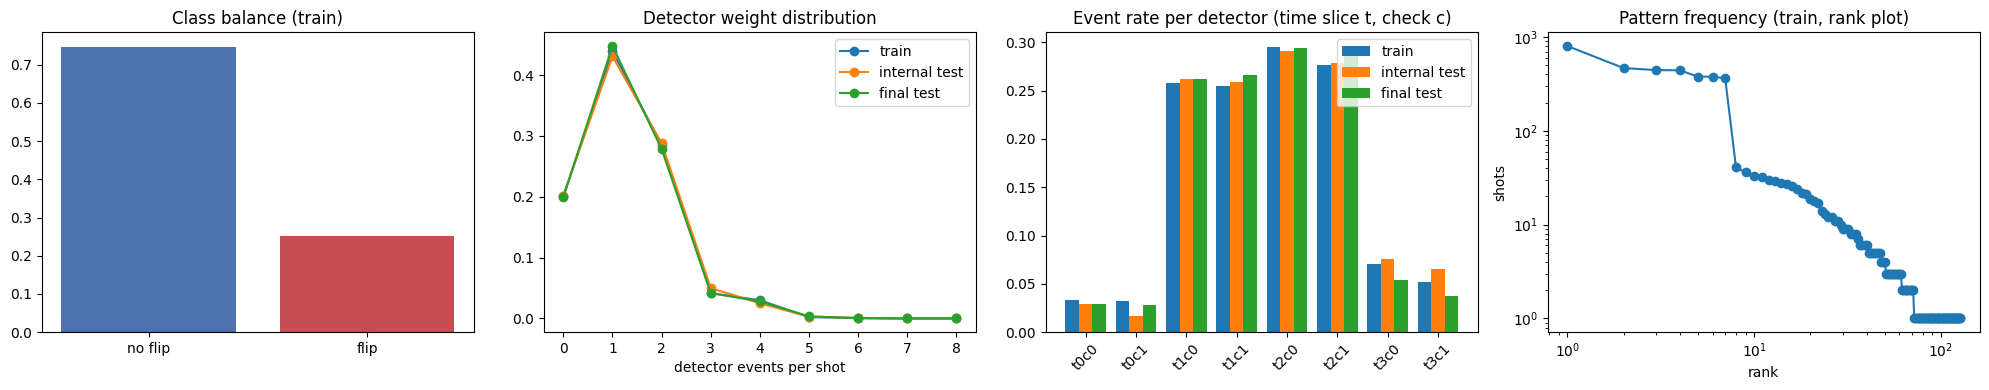

,shots,flip_rate
w,,
0,803,0.000000
1,1757,0.503130
2,1142,0.032399
3,166,0.457831
4,120,0.075000
5,9,0.444444
6,3,0.000000


INSIGHTS: 25.2% of train shots are flips, so the no-flip baseline already scores 74.8% accuracy. Only 127 distinct detector patterns occur in train, so each pattern is seen about 31 times on average: a lookup table is a strong competitor. 0.5% of internal-test shots and 0.8% of final-test shots have a pattern never seen in training (the places where decoders can differ most). Mean detector weight: train 1.27, internal test 1.28, final test 1.26; the final-test gap is a drift observation.


In [10]:
def pat_id(X):
    return (np.asarray(X).astype(int) * (1 << np.arange(8))).sum(1)
P_tr, P_te, P_fi = pat_id(X_tr), pat_id(X_te), pat_id(X_fi)
seen_tr = set(P_tr.tolist())
cov = lambda P: float(np.mean([p in seen_tr for p in P]))

bal = pd.DataFrame({"split": ["train", "internal_test"], "shots": [len(y_tr), len(y_te)], "flips": [y_tr.sum(), y_te.sum()],
                    "flip_rate": [y_tr.mean(), y_te.mean()], "no-flip baseline accuracy": [1 - y_tr.mean(), 1 - y_te.mean()]})
display(bal)
comp = (pd.DataFrame({"circuit": circ_tr, "y": y_tr}).groupby("circuit").agg(train_shots=("y", "size"), train_flip_rate=("y", "mean"))
        .join(pd.DataFrame({"circuit": circ_te, "y": y_te}).groupby("circuit").agg(test_shots=("y", "size"), test_flip_rate=("y", "mean"))))
display(comp)
patstats = pd.DataFrame({"split": ["train", "internal_test", "final_test"],
                         "distinct_patterns": [len(set(P_tr)), len(set(P_te)), len(set(P_fi))],
                         "mean_weight": [X_tr.sum(1).mean(), X_te.sum(1).mean(), X_fi.sum(1).mean()],
                         "share_zero_weight": [(X_tr.sum(1) == 0).mean(), (X_te.sum(1) == 0).mean(), (X_fi.sum(1) == 0).mean()],
                         "pattern_coverage_by_train": [1.0, cov(P_te), cov(P_fi)],
                         "share_shots_unseen_in_train": [0.0, 1 - cov(P_te), 1 - cov(P_fi)]})
display(patstats)

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].bar(["no flip", "flip"], [np.mean(y_tr == 0), np.mean(y_tr == 1)], color=["#4c72b0", "#c44e52"]); ax[0].set_title("Class balance (train)")
w_max = 8
for X, lab in [(X_tr, "train"), (X_te, "internal test"), (X_fi, "final test")]:
    ax[1].plot(range(w_max + 1), np.bincount(X.sum(1), minlength=w_max + 1)[:w_max + 1] / len(X), marker="o", label=lab)
ax[1].set_title("Detector weight distribution"); ax[1].set_xlabel("detector events per shot"); ax[1].legend()
act = np.stack([X_tr.mean(0).reshape(4, 2), X_te.mean(0).reshape(4, 2), X_fi.mean(0).reshape(4, 2)])
width = 0.27
for k, lab in enumerate(["train", "internal test", "final test"]):
    ax[2].bar(np.arange(8) + (k - 1) * width, act[k].reshape(-1), width, label=lab)
ax[2].set_xticks(range(8)); ax[2].set_xticklabels([f"t{t}c{i}" for t in range(4) for i in range(2)], rotation=45)
ax[2].set_title("Event rate per detector (time slice t, check c)"); ax[2].legend()
freq = pd.Series(P_tr).value_counts().to_numpy()
ax[3].loglog(np.arange(1, len(freq) + 1), freq, marker="o"); ax[3].set_title("Pattern frequency (train, rank plot)"); ax[3].set_xlabel("rank"); ax[3].set_ylabel("shots")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_eda.png", dpi=130); plt.show()

by_w = pd.DataFrame({"w": X_tr.sum(1), "y": y_tr}).groupby("w").y.agg(["size", "mean"]).rename(columns={"size": "shots", "mean": "flip_rate"})
display(by_w)
print("INSIGHTS:", f"{y_tr.mean():.1%} of train shots are flips, so the no-flip baseline already scores {1 - y_tr.mean():.1%} accuracy.",
      f"Only {len(set(P_tr))} distinct detector patterns occur in train, so each pattern is seen about {len(y_tr) / len(set(P_tr)):.0f} times on average: a lookup table is a strong competitor.",
      f"{1 - cov(P_te):.1%} of internal-test shots and {1 - cov(P_fi):.1%} of final-test shots have a pattern never seen in training (the places where decoders can differ most).",
      f"Mean detector weight: train {X_tr.sum(1).mean():.2f}, internal test {X_te.sum(1).mean():.2f}, final test {X_fi.sum(1).mean():.2f}; the final-test gap is a drift observation.")

## 05 Feature register

### Group every column and fix the allowed inputs
**Purpose:** Publish which column is an input, an identifier, provenance or a label/audit column, and make it impossible for a model to receive a label-derived column.

**Inputs:** All column names of the labelled tables and of the final-test table.

**Method:** A fixed register maps each column to a group and a decision. `guard_inputs` accepts only a numeric array of shape (n, 8) with entries in {0,1}, and `reject_label_columns` raises if a DataFrame with forbidden column names is passed to a model.

**Expected output:** The register table, the list of excluded columns and a passing self-test of the guard.

**Interpretation:** Only the 8 detector bits (equivalently the 6 raw syndrome bits) are ever shown to M0, M1 and M2. Everything else is for splitting, EDA or reporting.

**Failure mode:** If a future edit passes a DataFrame or a wrong width into a model the guard raises instead of silently training on a leaked column.

In [11]:
register_rows = [
 ("detectors", "query input", "USED (M0, M1, M2)", "8 detector events of one shot, the only model input"),
 ("syndrome", "query input", "NOT USED (redundant)", "equivalent 6-bit representation of the same history; kept for the hardware parser tests"),
 ("record_id", "identifier", "excluded", "joining and reporting only"),
 ("shot_id", "identifier", "excluded", "shot index inside its circuit, meaningless"),
 ("job_id", "provenance", "excluded", "constant, reporting only"),
 ("backend", "provenance", "excluded", "constant, reporting only"),
 ("distance", "provenance", "excluded", "constant (3)"),
 ("rounds", "provenance", "excluded", "constant (3)"),
 ("observable_error", "label", "TARGET ONLY", "training target and evaluation reference"),
 ("final_data", "label / audit", "FORBIDDEN as input", "determines the label exactly"),
 ("initial_bit", "label / audit", "FORBIDDEN as input", "determines the label exactly"),
 ("fault_type", "label / audit", "FORBIDDEN as input", "describes the injected cause"),
 ("injected_x_qubit", "label / audit", "FORBIDDEN as input", "describes the injected cause"),
 ("injected_after_round", "label / audit", "FORBIDDEN as input", "describes the injected cause"),
 ("fault_label", "label / audit", "FORBIDDEN as input", "describes the injected cause"),
 ("circuit_name", "label / audit", "stratification + EDA only", "encodes the injected fault; used only to stratify splits"),
 ("detector_event_count", "label / audit", "FORBIDDEN as input", "derived from the input, EDA only"),
 ("has_detection_event", "label / audit", "FORBIDDEN as input", "derived from the input, EDA only"),
]
register = pd.DataFrame(register_rows, columns=["column", "group", "decision", "reason"])
display(register)
unregistered = [c for c in tr.columns if c not in set(register.column)]
assert not unregistered, f"Unregistered columns: {unregistered}"
FORBIDDEN_INPUT_COLUMNS = set(register[register.decision.str.contains("FORBIDDEN|TARGET|stratification|excluded")].column)

def reject_label_columns(obj):
    if isinstance(obj, (pd.DataFrame, pd.Series)):
        names = set(obj.columns) if isinstance(obj, pd.DataFrame) else {obj.name}
        bad = names & FORBIDDEN_INPUT_COLUMNS
        if bad:
            raise ValueError(f"Label/identifier columns are not allowed as model input: {sorted(bad)}")
        raise TypeError("Pass a plain (n,8) array of detector bits, not a DataFrame/Series.")

def guard_inputs(X):
    reject_label_columns(X)
    X = np.asarray(X)
    if X.ndim == 1:
        X = X[None, :]
    if X.ndim != 2 or X.shape[1] != 8:
        raise ValueError(f"Expected shape (n, 8) detector bits, got {X.shape}")
    if not np.isin(X, (0, 1)).all():
        raise ValueError("Detector inputs must be 0/1")
    return X.astype(np.int8)

# self-test of the guard
for bad in (tr, tr[["observable_error"]], np.zeros((3, 7)), np.full((2, 8), 2)):
    try:
        guard_inputs(bad); raise SystemExit("guard failed to reject")
    except (ValueError, TypeError):
        pass
assert guard_inputs(X_tr[:3]).shape == (3, 8)
excluded = register[~register.decision.str.startswith("USED")].column.tolist()
print("Excluded from inputs:", excluded)
print("\nINSIGHTS:", f"{len(register)} columns registered; exactly 1 column (`detectors`) feeds the models. The guard rejected DataFrames, label columns, wrong width and non-binary values.")

,column,group,decision,reason
0,detectors,query input,"USED (M0, M1, M2)","8 detector events of one shot, the only model ..."
1,syndrome,query input,NOT USED (redundant),equivalent 6-bit representation of the same hi...
2,record_id,identifier,excluded,joining and reporting only
3,shot_id,identifier,excluded,"shot index inside its circuit, meaningless"
4,job_id,provenance,excluded,"constant, reporting only"
5,backend,provenance,excluded,"constant, reporting only"
6,distance,provenance,excluded,constant (3)
7,rounds,provenance,excluded,constant (3)
8,observable_error,label,TARGET ONLY,training target and evaluation reference
9,final_data,label / audit,FORBIDDEN as input,determines the label exactly


Excluded from inputs: ['syndrome', 'record_id', 'shot_id', 'job_id', 'backend', 'distance', 'rounds', 'observable_error', 'final_data', 'initial_bit', 'fault_type', 'injected_x_qubit', 'injected_after_round', 'fault_label', 'circuit_name', 'detector_event_count', 'has_detection_event']

INSIGHTS: 18 columns registered; exactly 1 column (`detectors`) feeds the models. The guard rejected DataFrames, label columns, wrong width and non-binary values.


## 06 Matching graph (M0)

### Build the PyMatching graph and unit-test it on hand-made syndromes
**Purpose:** Construct the decoding graph of section 3.7 of the task and confirm it behaves as the physics says on tiny examples.

**Inputs:** Edge weights: data edges weight 1, measurement (temporal) edges weight `ratio` (selected later on training data).

**Method:** Nodes $n(t,i)=2t+i$. Boundary edges at $n(t,0)$ (carrying the logical observable, fault id 0) and at $n(t,1)$; an edge $n(t,0)\!-\!n(t,1)$ for each $t$; temporal edges $n(t,i)\!-\!n(t+1,i)$ for $t\le2$. MWPM returns the correction with minimum total weight $\sum w_e$; the prediction is the parity of the observable-carrying edges used.

**Expected output:** A list of hand-made syndromes with expected and obtained predictions, all passing.

**Interpretation:** Single events next to the logical-carrying boundary imply a logical flip; events next to the other boundary do not; neighbouring pairs are explained by one middle-qubit error.

**Failure mode:** A wrong boundary assignment would flip the meaning of every prediction; the tests are meant to catch exactly that.

In [12]:
def node(t, i):
    return 2 * t + i

def build_matching(ratio=1.0):
    m = pymatching.Matching()
    w_data, w_meas = 1.0, float(ratio)
    for t in range(4):
        m.add_boundary_edge(node(t, 0), fault_ids={0}, weight=w_data)   # X on data qubit 0 flips the logical observable
        m.add_boundary_edge(node(t, 1), weight=w_data)                    # X on data qubit 2 does not
        m.add_edge(node(t, 0), node(t, 1), weight=w_data)                 # X on the middle data qubit
    for t in range(3):
        for i in range(2):
            m.add_edge(node(t, i), node(t + 1, i), weight=w_meas)         # faulty parity measurement
    return m

def mwpm_predict(matcher, X):
    X = guard_inputs(X).astype(np.uint8)
    return matcher.decode_batch(X).reshape(len(X), -1)[:, 0].astype(int)

def vec(*events):
    v = np.zeros(8, np.uint8)
    for t, i in events:
        v[node(t, i)] = 1
    return v

M_unit = build_matching(1.0)
tests = [
 ("no events", [], 0),
 ("single event at n(0,0) (logical boundary)", [(0, 0)], 1),
 ("single event at n(0,1) (other boundary)", [(0, 1)], 0),
 ("single event at n(3,0)", [(3, 0)], 1),
 ("pair n(0,0)+n(0,1): middle-qubit error", [(0, 0), (0, 1)], 0),
 ("pair n(0,0)+n(1,0): measurement error", [(0, 0), (1, 0)], 0),
 ("n(0,0)+n(2,1): two boundaries cheaper than a long path", [(0, 0), (2, 1)], 1),
 ("n(1,1) alone", [(1, 1)], 0),
]
rows = []
for name, ev, exp in tests:
    got = int(mwpm_predict(M_unit, vec(*ev)[None, :])[0])
    rows.append((name, exp, got, "PASS" if got == exp else "FAIL"))
unit = pd.DataFrame(rows, columns=["syndrome", "expected flip", "matching says", "result"])
display(unit)
assert (unit.result == "PASS").all()
print("Graph:", M_unit.num_nodes, "nodes,", M_unit.num_edges, "edges,", M_unit.num_fault_ids, "fault id(s)")
print("\nINSIGHTS:", f"{(unit.result == 'PASS').sum()}/{len(unit)} hand-made syndromes behave as expected; the graph has {M_unit.num_edges} edges over {M_unit.num_nodes} detector nodes plus the boundary.")

,syndrome,expected flip,matching says,result
0,no events,0,0,PASS
1,"single event at n(0,0) (logical boundary)",1,1,PASS
2,"single event at n(0,1) (other boundary)",0,0,PASS
3,"single event at n(3,0)",1,1,PASS
4,"pair n(0,0)+n(0,1): middle-qubit error",0,0,PASS
5,"pair n(0,0)+n(1,0): measurement error",0,0,PASS
6,"n(0,0)+n(2,1): two boundaries cheaper than a l...",1,1,PASS
7,"n(1,1) alone",0,0,PASS


Graph: 8 nodes, 18 edges, 1 fault id(s)

INSIGHTS: 8/8 hand-made syndromes behave as expected; the graph has 18 edges over 8 detector nodes plus the boundary.


## 07 M0: controls and matching

### No-flip control, pattern-lookup control and MWPM with training-selected weights
**Purpose:** Build the reference decoders. The no-flip control is the 'before decoding' number; the lookup control shows what a pure table of training patterns achieves; MWPM is the classical algorithm.

**Inputs:** `X_tr`, `y_tr`, `circuit_name` (stratification only).

**Method:** Logical error rate $\mathrm{LER}=\frac1n\sum_j \mathbb 1[\hat y_j\ne y_j]$. Lookup: for each distinct pattern predict the majority training label (ties and unseen patterns predict 0). Matching: ratio $r$ of measurement-edge weight to data-edge weight chosen from a grid by 5-fold stratified cross-validated LER on **train only**; ties go to the $r$ closest to 1.

**Expected output:** A table of cross-validated LER for the no-flip control, the lookup control and each matching weight ratio, and the chosen ratio.

**Interpretation:** Cross-validation inside train keeps `internal_test_1000` untouched. If several ratios tie within noise the choice is not meaningful, and the table shows that.

**Failure mode:** Lookup scored on its own training rows would look perfect; that is why it is scored by cross-validation.

In [13]:
from sklearn.model_selection import StratifiedKFold, train_test_split

def ler(y, p):
    return float(np.mean(np.asarray(p) != np.asarray(y)))

class PatternLookup:
    def fit(self, X, y):
        d = pd.DataFrame({"p": pat_id(X), "y": np.asarray(y)}).groupby("p").y.mean()
        self.table = {int(p): int(v > 0.5) for p, v in d.items()}   # ties (exactly 0.5) -> 0
        return self
    def predict(self, X):
        P = pat_id(guard_inputs(X))
        seen = np.array([int(p) in self.table for p in P])
        pred = np.array([self.table.get(int(p), 0) for p in P], dtype=int)
        return pred, seen

def ratio_table(X, y, strata, grid):
    skf = StratifiedKFold(CONFIG["cv_folds"], shuffle=True, random_state=SEED)
    folds = list(skf.split(X, strata))
    rows = []
    for r in grid:
        pred = mwpm_predict(build_matching(r), X)
        per = [ler(y[b], pred[b]) for _, b in folds]
        rows.append(dict(ratio=r, cv_LER_mean=np.mean(per), cv_LER_sd=np.std(per), LER_all=ler(y, pred)))
    return pd.DataFrame(rows)

def pick_ratio(tab):
    best = tab.cv_LER_mean.min()
    cand = tab[np.isclose(tab.cv_LER_mean, best)]
    return float(cand.iloc[(cand.ratio - 1.0).abs().argsort().iloc[0]].ratio)

skf = StratifiedKFold(CONFIG["cv_folds"], shuffle=True, random_state=SEED)
noflip_cv = [ler(y_tr[b], np.zeros(len(b), int)) for _, b in skf.split(X_tr, circ_tr)]
lookup_cv, unseen_cv = [], []
for a, b in skf.split(X_tr, circ_tr):
    pr, seen = PatternLookup().fit(X_tr[a], y_tr[a]).predict(X_tr[b])
    lookup_cv.append(ler(y_tr[b], pr)); unseen_cv.append(1 - seen.mean())
ratios = ratio_table(X_tr, y_tr, circ_tr, CONFIG["matching_ratio_grid"])
RATIO_FULL = pick_ratio(ratios)
ctrl = pd.DataFrame([dict(method="no-flip control (raw LER)", cv_LER_mean=np.mean(noflip_cv), cv_LER_sd=np.std(noflip_cv)),
                     dict(method="pattern-lookup control", cv_LER_mean=np.mean(lookup_cv), cv_LER_sd=np.std(lookup_cv))] +
                    [dict(method=f"MWPM ratio={r.ratio}", cv_LER_mean=r.cv_LER_mean, cv_LER_sd=r.cv_LER_sd) for r in ratios.itertuples()])
display(ctrl)
M0_MATCHER = build_matching(RATIO_FULL)
LOOKUP_FULL = PatternLookup().fit(X_tr, y_tr)
print("Chosen measurement/data weight ratio (train only):", RATIO_FULL)
print("\nINSIGHTS:", f"Cross-validated on train, no decoding gives LER {np.mean(noflip_cv):.3f}, the lookup control {np.mean(lookup_cv):.3f} "
      f"(about {np.mean(unseen_cv):.1%} of held-out shots hit an unseen pattern), and matching with ratio {RATIO_FULL} gives "
      f"{ratios.set_index('ratio').loc[RATIO_FULL, 'cv_LER_mean']:.3f}. Spread of matching LER across ratios: "
      f"{ratios.cv_LER_mean.max() - ratios.cv_LER_mean.min():.3f}, fold sd about {ratios.cv_LER_sd.mean():.3f}, so ratio differences smaller than that are noise.")

,method,cv_LER_mean,cv_LER_sd
0,no-flip control (raw LER),0.25250,0.008329
1,pattern-lookup control,0.01700,0.003021
2,MWPM ratio=0.5,0.02075,0.005339
3,MWPM ratio=0.75,0.02075,0.005339
4,MWPM ratio=1.0,0.02875,0.004257
5,MWPM ratio=1.25,0.02900,0.002669
6,MWPM ratio=1.5,0.02900,0.002669
7,MWPM ratio=2.0,0.02975,0.003102
8,MWPM ratio=3.0,0.02975,0.003102


Chosen measurement/data weight ratio (train only): 0.75

INSIGHTS: Cross-validated on train, no decoding gives LER 0.253, the lookup control 0.017 (about 1.5% of held-out shots hit an unseen pattern), and matching with ratio 0.75 gives 0.021. Spread of matching LER across ratios: 0.009, fold sd about 0.004, so ratio differences smaller than that are noise.


## 08 M1: MLP syndrome classifier

### Cross-validated MLP search, class weights, threshold and ablations
**Purpose:** Train a small multilayer perceptron on the 8 detector bits, choose its size and weight decay by stratified cross-validation inside train, and quantify the effect of class weights, the tuned threshold and network size.

**Inputs:** `X_tr`, `y_tr`, `circuit_name` (stratification only). Search space: hidden layers (16), (32,32), (64,64), (128,64,32); L2 weight decay 1e-4 and 1e-2.

**Method:** Network $p(x)=\sigma(f_\theta(x))$ trained by Adam on binary cross-entropy. Class weighting: each epoch the training rows are resampled with probability proportional to $w_c=\frac{n}{2n_c}$ (balanced), which is equivalent in expectation to a weighted loss. Early stopping on a held-out 20 % validation slice (patience 15). Decision threshold $\tau$ minimises LER on that validation slice (ties go to the $\tau$ closest to 0.5). Inside every outer CV fold the network is fitted on 80 % of the fold's training part and early-stopped / thresholded on the other 20 %; the outer held-out part is touched only for scoring.

**Expected output:** CV table of all settings, an ablation table, and the frozen M1 training record.

**Interpretation:** The ablation shows whether class weights, a tuned threshold and a bigger network are worth anything on this tiny input space.

**Failure mode:** With only about 130 distinct inputs the MLP can at best reproduce what the lookup table does; do not expect a miracle, and report it as measured.

In [14]:
from sklearn.neural_network import MLPClassifier

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))
def wlogloss(y, p, balanced):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    l = -(y * np.log(p) + (1 - y) * np.log(1 - p))
    if balanced:
        w = np.where(y == 1, 0.5 / max(y.mean(), 1e-9), 0.5 / max(1 - y.mean(), 1e-9))
        return float(np.sum(w * l) / np.sum(w))
    return float(l.mean())

def best_threshold(y, p, grid=np.linspace(0.02, 0.98, 97)):
    errs = np.array([np.mean((p >= t) != y) for t in grid])
    cand = grid[np.isclose(errs, errs.min())]
    return float(cand[np.abs(cand - 0.5).argmin()])

class MLPDecoder:
    def __init__(self, hidden=(32, 32), alpha=1e-3, class_weight=True, seed=SEED):
        self.hidden, self.alpha, self.class_weight, self.seed = tuple(hidden), alpha, class_weight, seed
    def fit(self, X, y, Xv, yv):
        X, Xv = guard_inputs(X).astype(float), guard_inputs(Xv).astype(float)
        y, yv = np.asarray(y).astype(int), np.asarray(yv).astype(int)
        rng = np.random.default_rng(self.seed)
        clf = MLPClassifier(hidden_layer_sizes=self.hidden, alpha=self.alpha, solver="adam", learning_rate_init=CONFIG["mlp_lr"],
                            batch_size=CONFIG["mlp_batch"], random_state=self.seed)
        n = len(X)
        if self.class_weight:
            w = np.where(y == 1, 0.5 / y.mean(), 0.5 / (1 - y.mean())); w = w / w.sum()
        best, best_clf, wait = np.inf, None, 0
        for ep in range(CONFIG["mlp_max_epochs"]):
            idx = rng.choice(n, size=n, p=w) if self.class_weight else rng.permutation(n)
            clf.partial_fit(X[idx], y[idx], classes=[0, 1])
            vl = wlogloss(yv, clf.predict_proba(Xv)[:, 1], self.class_weight)
            if vl < best - 1e-4:
                best, best_clf, wait = vl, deepcopy(clf), 0
            else:
                wait += 1
                if wait >= CONFIG["mlp_patience"]:
                    break
        self.clf, self.epochs, self.val_loss = best_clf, ep + 1, best
        self.n_params = int(sum(c.size for c in self.clf.coefs_) + sum(b.size for b in self.clf.intercepts_))
        return self
    def predict_proba(self, X):
        return self.clf.predict_proba(guard_inputs(X).astype(float))[:, 1]

def cv_mlp(hidden, alpha, class_weight, X, y, strata):
    skf = StratifiedKFold(CONFIG["cv_folds"], shuffle=True, random_state=SEED)
    out = []
    for k, (a, b) in enumerate(skf.split(X, strata)):
        fa, va = train_test_split(a, test_size=0.2, stratify=strata[a], random_state=SEED + k)
        mdl = MLPDecoder(hidden, alpha, class_weight, seed=SEED + k).fit(X[fa], y[fa], X[va], y[va])
        thr = best_threshold(y[va], mdl.predict_proba(X[va]))
        pb = mdl.predict_proba(X[b])
        out.append(dict(ler_thr05=np.mean((pb >= 0.5) != y[b]), ler_tuned=np.mean((pb >= thr) != y[b]), thr=thr, epochs=mdl.epochs, n_params=mdl.n_params))
    return pd.DataFrame(out)

t0 = time.time()
rows = []
for hidden in CONFIG["mlp_sizes"]:
    for alpha in CONFIG["mlp_alphas"]:
        r = cv_mlp(hidden, alpha, True, X_tr, y_tr, circ_tr)
        rows.append(dict(hidden=str(hidden), alpha=alpha, class_weight=True, params=int(r.n_params.mean()), cv_LER_tuned=r.ler_tuned.mean(), cv_LER_sd=r.ler_tuned.std(),
                         cv_LER_thr0_5=r.ler_thr05.mean(), mean_threshold=r.thr.mean(), mean_epochs=r.epochs.mean()))
cvtab = pd.DataFrame(rows)
display(cvtab)
bestv = cvtab.cv_LER_tuned.min()
cand = cvtab[np.isclose(cvtab.cv_LER_tuned, bestv)].sort_values("params")
M1_CFG = dict(hidden=eval(cand.iloc[0].hidden), alpha=float(cand.iloc[0].alpha), class_weight=True)
print("Chosen M1 setting (lowest CV LER, ties to the smaller network):", M1_CFG, f"| search time {time.time() - t0:.0f}s")

# ablations (cross-validated inside train only)
r_noW = cv_mlp(M1_CFG["hidden"], M1_CFG["alpha"], False, X_tr, y_tr, circ_tr)
best_row = cvtab[(cvtab.hidden == str(M1_CFG["hidden"])) & (cvtab.alpha == M1_CFG["alpha"])].iloc[0]
abl = [dict(variant="chosen: class weights + tuned threshold", cv_LER=best_row.cv_LER_tuned),
       dict(variant="class weights + threshold 0.5", cv_LER=best_row.cv_LER_thr0_5),
       dict(variant="no class weights + tuned threshold", cv_LER=r_noW.ler_tuned.mean()),
       dict(variant="no class weights + threshold 0.5", cv_LER=r_noW.ler_thr05.mean())]
for hidden in CONFIG["mlp_sizes"]:
    sub = cvtab[cvtab.hidden == str(hidden)]
    abl.append(dict(variant=f"network size {hidden} (best weight decay)", cv_LER=sub.cv_LER_tuned.min()))
ablation = pd.DataFrame(abl)
display(ablation)
print("\nINSIGHTS:", f"Best CV LER {bestv:.3f} with hidden layers {M1_CFG['hidden']} and weight decay {M1_CFG['alpha']}. "
      f"Spread of CV LER over all {len(cvtab)} settings is only {cvtab.cv_LER_tuned.max() - cvtab.cv_LER_tuned.min():.3f}, "
      f"versus a fold sd of about {cvtab.cv_LER_sd.mean():.3f}. Tuned vs 0.5 threshold: {best_row.cv_LER_tuned:.3f} vs {best_row.cv_LER_thr0_5:.3f}; "
      f"without class weights (tuned): {r_noW.ler_tuned.mean():.3f}.")

,hidden,alpha,class_weight,params,cv_LER_tuned,cv_LER_sd,cv_LER_thr0_5,mean_threshold,mean_epochs
0,"(16,)",0.0001,True,161,0.02250,0.006673,0.03750,0.724,149.4
1,"(16,)",0.0100,True,161,0.02175,0.006034,0.04150,0.696,149.0
2,"(32, 32)",0.0001,True,1377,0.02125,0.006435,0.02625,0.796,61.2
3,"(32, 32)",0.0100,True,1377,0.01975,0.006212,0.02400,0.812,77.4
4,"(64, 64)",0.0001,True,4801,0.01850,0.003236,0.02450,0.784,47.4
5,"(64, 64)",0.0100,True,4801,0.01750,0.003644,0.02600,0.814,50.4
6,"(128, 64, 32)",0.0001,True,11521,0.02050,0.004384,0.02900,0.662,32.0
7,"(128, 64, 32)",0.0100,True,11521,0.01950,0.003812,0.02675,0.772,34.2


Chosen M1 setting (lowest CV LER, ties to the smaller network): {'hidden': (64, 64), 'alpha': 0.01, 'class_weight': True} | search time 42s


,variant,cv_LER
0,chosen: class weights + tuned threshold,0.01750
1,class weights + threshold 0.5,0.02600
2,no class weights + tuned threshold,0.01775
3,no class weights + threshold 0.5,0.01850
4,"network size (16,) (best weight decay)",0.02175
5,"network size (32, 32) (best weight decay)",0.01975
6,"network size (64, 64) (best weight decay)",0.01750
7,"network size (128, 64, 32) (best weight decay)",0.01950



INSIGHTS: Best CV LER 0.017 with hidden layers (64, 64) and weight decay 0.01. Spread of CV LER over all 8 settings is only 0.005, versus a fold sd of about 0.005. Tuned vs 0.5 threshold: 0.017 vs 0.026; without class weights (tuned): 0.018.


### Fit and freeze the final M1 on train
**Purpose:** Train the chosen network on the full training file with an internal validation slice and fix its threshold.

**Inputs:** `X_tr`, `y_tr`, `M1_CFG`.

**Method:** 80 % fit / 20 % validation split of train (stratified by circuit, fixed seed). Early stopping and the threshold use the validation slice only.

**Expected output:** The training record: epochs, validation loss, parameters, threshold.

**Interpretation:** This object is what is frozen and later used for the final-test predictions.

**Failure mode:** Do not refit after looking at internal-test scores; any change after that would have to be labelled post-hoc.

In [15]:
fit_i, val_i = train_test_split(np.arange(len(X_tr)), test_size=0.2, stratify=circ_tr, random_state=SEED)
M1_MODEL = MLPDecoder(M1_CFG["hidden"], M1_CFG["alpha"], M1_CFG["class_weight"], seed=SEED).fit(X_tr[fit_i], y_tr[fit_i], X_tr[val_i], y_tr[val_i])
M1_THR = best_threshold(y_tr[val_i], M1_MODEL.predict_proba(X_tr[val_i]))
def m1_proba(X): return M1_MODEL.predict_proba(X)
def m1_predict(X): return (m1_proba(X) >= M1_THR).astype(int)
M1_RECORD = dict(config=M1_CFG, epochs=M1_MODEL.epochs, val_logloss=M1_MODEL.val_loss, n_params=M1_MODEL.n_params, threshold=M1_THR,
                 fit_rows=len(fit_i), val_rows=len(val_i), val_LER=ler(y_tr[val_i], m1_predict(X_tr[val_i])))
display(pd.Series(M1_RECORD, name="M1 training record").to_frame())
print("\nINSIGHTS:", f"M1 stopped after {M1_MODEL.epochs} epochs with {M1_MODEL.n_params} parameters; the threshold {M1_THR:.2f} (chosen on the validation slice only) gives validation LER {M1_RECORD['val_LER']:.3f}.")

,M1 training record
config,"{'hidden': (64, 64), 'alpha': 0.01, 'class_wei..."
epochs,58
val_logloss,0.102852
n_params,4801
threshold,0.84
fit_rows,3200
val_rows,800
val_LER,0.01375



INSIGHTS: M1 stopped after 58 epochs with 4801 parameters; the threshold 0.84 (chosen on the validation slice only) gives validation LER 0.014.


## 09 M2: the MOR router

### Fit M2 on three disjoint slices of train
**Purpose:** Build the five-stage router: difficulty classes, neural pre-decoder, per-class routing, Platt calibration, output record.

**Inputs:** `X_tr`, `y_tr`, `circuit_name` (stratification only). Slices: 60 % fit, 20 % validation, 20 % routing, stratified by circuit, seed fixed.

**Method:** Stage 1: weight $w$ gives TRIVIAL ($w=0$), EASY ($w\in\{1,2\}$), HARD ($w\ge3$), thresholds fixed in advance. Stage 2: the M1 network is trained on the fit slice, early-stopped on the validation slice. MWPM ratio is chosen on the fit slice only; an exact cache stores MWPM outputs for fit-slice patterns (checked against live matching). Stage 4: Platt scaling $q=\sigma(a\,\mathrm{logit}(p)+b)$ with $(a,b)$ minimising log loss on the validation slice; the neural threshold minimises LER on calibrated validation probabilities. Stage 3: for each class count each candidate's errors (identity, MWPM, neural) on the **routing** slice and pick the fewest, ties to the cheapest (identity, then MWPM, then neural).

**Expected output:** Slice sizes with a disjointness check, the routing table, per-class candidate error counts, Platt parameters, ECE before and after, and the cache check.

**Interpretation:** The router can only claim a gain if its per-class choice (made on data the networks never trained on) transfers to the test shots; the benchmark section measures that.

**Failure mode:** If a class has very few routing shots its choice is noisy; the printed counts show how much evidence each choice rests on.

In [16]:
from scipy.optimize import minimize

def difficulty_of(X):
    w = np.asarray(X).sum(1)
    return np.where(w == 0, "TRIVIAL", np.where(w <= 2, "EASY", "HARD"))
CLASSES, CHEAPNESS = ["TRIVIAL", "EASY", "HARD"], ["IDENTITY", "MWPM", "NEURAL"]

def fit_platt(p, y):
    z = logit(p)
    def nll(ab):
        q = np.clip(sigmoid(ab[0] * z + ab[1]), 1e-9, 1 - 1e-9)
        return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))
    res = minimize(nll, x0=[1.0, 0.0], method="L-BFGS-B")
    return float(res.x[0]), float(res.x[1])

def reliability(p, y, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    ids = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    rows = []
    for b in range(bins):
        m = ids == b
        if m.any():
            rows.append((p[m].mean(), y[m].mean(), int(m.sum())))
    return np.array(rows)
def ece(p, y, bins=10):
    r = reliability(p, y, bins)
    return float(np.sum(r[:, 2] / r[:, 2].sum() * np.abs(r[:, 0] - r[:, 1])))

class MORRouter:
    def __init__(self, ratio, mlp, platt, thr, routing, fit_patterns_pred):
        self.ratio, self.mlp, self.platt, self.thr, self.routing = ratio, mlp, platt, thr, routing
        self.cache = dict(fit_patterns_pred); self.cache_hits = 0; self.cache_misses = 0; self._matcher = None
    @property
    def matcher(self):
        if self._matcher is None:
            self._matcher = build_matching(self.ratio)
        return self._matcher
    def __getstate__(self):
        d = self.__dict__.copy(); d["_matcher"] = None; return d
    def calibrate(self, p):
        return sigmoid(self.platt[0] * logit(p) + self.platt[1])
    def mwpm(self, X, use_cache=True):
        X = guard_inputs(X)
        if not use_cache:
            return mwpm_predict(self.matcher, X)
        P = pat_id(X)
        hit = np.array([int(p) in self.cache for p in P])
        out = np.zeros(len(X), int)
        if hit.any():
            out[hit] = [self.cache[int(p)] for p in P[hit]]
        if (~hit).any():
            out[~hit] = mwpm_predict(self.matcher, X[~hit])
        self.cache_hits += int(hit.sum()); self.cache_misses += int((~hit).sum())
        return out
    def predict(self, X):
        X = guard_inputs(X); n = len(X)
        cls = difficulty_of(X)
        dec = np.array([self.routing[c] for c in cls], dtype=object)
        pred = np.zeros(n, int); pcal = np.full(n, np.nan)
        m = dec == "MWPM"
        if m.any():
            pred[m] = self.mwpm(X[m])
        nn = dec == "NEURAL"
        if nn.any():
            q = self.calibrate(self.mlp.predict_proba(X[nn])); pcal[nn] = q; pred[nn] = (q >= self.thr).astype(int)
        return pd.DataFrame(dict(predicted_flip=pred, difficulty=cls, decoder=dec, p_cal=pcal))

def fit_m2(X, y, strata, mlp_cfg, seed=SEED):
    idx = np.arange(len(X))
    fit_idx, rest = train_test_split(idx, test_size=0.4, stratify=strata, random_state=seed)
    val_idx, route_idx = train_test_split(rest, test_size=0.5, stratify=strata[rest], random_state=seed)
    assert not (set(fit_idx) & set(val_idx)) and not (set(fit_idx) & set(route_idx)) and not (set(val_idx) & set(route_idx))
    # MWPM ratio: fit slice only
    tab = ratio_table(X[fit_idx], y[fit_idx], strata[fit_idx], CONFIG["matching_ratio_grid"])
    ratio = pick_ratio(tab)
    live = build_matching(ratio)
    uniq, first = np.unique(pat_id(X[fit_idx]), return_index=True)
    cache = dict(zip(uniq.tolist(), mwpm_predict(live, X[fit_idx][first]).tolist()))
    # neural pre-decoder: fit slice, early stopping on validation slice
    mlp = MLPDecoder(mlp_cfg["hidden"], mlp_cfg["alpha"], mlp_cfg["class_weight"], seed=seed).fit(X[fit_idx], y[fit_idx], X[val_idx], y[val_idx])
    p_val = mlp.predict_proba(X[val_idx])
    platt = fit_platt(p_val, y[val_idx])
    q_val = sigmoid(platt[0] * logit(p_val) + platt[1])
    thr = best_threshold(y[val_idx], q_val)
    # router: routing slice, per-class candidate errors
    Xr, yr = X[route_idx], y[route_idx]
    cls_r = difficulty_of(Xr)
    cand_pred = {"IDENTITY": np.zeros(len(Xr), int), "MWPM": mwpm_predict(live, Xr),
                 "NEURAL": (sigmoid(platt[0] * logit(mlp.predict_proba(Xr)) + platt[1]) >= thr).astype(int)}
    err_rows, routing = [], {}
    for c in CLASSES:
        m = cls_r == c
        errs = {d: int((cand_pred[d][m] != yr[m]).sum()) for d in CHEAPNESS}
        best = min(errs.values())
        routing[c] = next(d for d in CHEAPNESS if errs[d] == best)   # ties -> cheapest first
        err_rows.append(dict(difficulty=c, routing_shots=int(m.sum()), **{f"errors_{d}": errs[d] for d in CHEAPNESS}, chosen=routing[c]))
    router = MORRouter(ratio, mlp, platt, thr, routing, cache)
    info = dict(fit_idx=fit_idx, val_idx=val_idx, route_idx=route_idx, ratio_table=tab, route_errors=pd.DataFrame(err_rows), p_val=p_val, q_val=q_val)
    return router, info

M2_ROUTER, M2_INFO = fit_m2(X_tr, y_tr, circ_tr, M1_CFG)
sl = pd.DataFrame({"slice": ["fit", "validation", "routing"],
                   "shots": [len(M2_INFO["fit_idx"]), len(M2_INFO["val_idx"]), len(M2_INFO["route_idx"])],
                   "flip_rate": [y_tr[M2_INFO[k]].mean() for k in ("fit_idx", "val_idx", "route_idx")]})
display(sl)
print("Disjointness of the three slices: verified by assertion inside fit_m2")
print("Difficulty thresholds (fixed in advance):", CONFIG["difficulty"])
display(M2_INFO["route_errors"])
print("Routing table:", M2_ROUTER.routing)
print(f"MWPM ratio chosen on the fit slice: {M2_ROUTER.ratio} | Platt a={M2_ROUTER.platt[0]:.3f}, b={M2_ROUTER.platt[1]:.3f} | calibrated neural threshold: {M2_ROUTER.thr:.2f}")

# calibration on the routing slice (not used to fit Platt)
ri = M2_INFO["route_idx"]
p_raw = M2_ROUTER.mlp.predict_proba(X_tr[ri]); p_cal = M2_ROUTER.calibrate(p_raw)
ece_before, ece_after = ece(p_raw, y_tr[ri]), ece(p_cal, y_tr[ri])
print(f"ECE on the routing slice: raw MLP {ece_before:.3f} -> after Platt {ece_after:.3f}")

# exact cache vs live matching
M2_ROUTER.cache_hits = M2_ROUTER.cache_misses = 0
chk_X = np.vstack([X_tr, X_te])
identical = bool(np.array_equal(M2_ROUTER.mwpm(chk_X, use_cache=True), M2_ROUTER.mwpm(chk_X, use_cache=False)))
hit_rate = M2_ROUTER.cache_hits / max(1, M2_ROUTER.cache_hits + M2_ROUTER.cache_misses)
print(f"Cache gives identical predictions to live matching on {len(chk_X)} shots: {identical} | cache hit rate {hit_rate:.1%}")
assert identical
re_ = M2_INFO["route_errors"]
print("\nINSIGHTS:", "Routing table " + ", ".join(f"{r.difficulty}->{r.chosen}" for r in re_.itertuples()) + ". "
      + "Evidence per class (routing shots): " + ", ".join(f"{r.difficulty} {r.routing_shots}" for r in re_.itertuples()) + ". "
      + f"Platt scaling moves ECE from {ece_before:.3f} to {ece_after:.3f} on shots it was not fitted on. The cache is exact and hits {hit_rate:.0%} of shots.")

,slice,shots,flip_rate
0,fit,2400,0.245833
1,validation,800,0.262500
2,routing,800,0.262500


Disjointness of the three slices: verified by assertion inside fit_m2
Difficulty thresholds (fixed in advance): {'trivial': 'w == 0', 'easy': 'w in {1, 2}', 'hard': 'w >= 3'}


,difficulty,routing_shots,errors_IDENTITY,errors_MWPM,errors_NEURAL,chosen
0,TRIVIAL,155,0,0,0,IDENTITY
1,EASY,593,192,5,4,NEURAL
2,HARD,52,18,13,12,NEURAL


Routing table: {'TRIVIAL': 'IDENTITY', 'EASY': 'NEURAL', 'HARD': 'NEURAL'}
MWPM ratio chosen on the fit slice: 0.75 | Platt a=0.838, b=-0.993 | calibrated neural threshold: 0.50
ECE on the routing slice: raw MLP 0.023 -> after Platt 0.009
Cache gives identical predictions to live matching on 5000 shots: True | cache hit rate 99.0%

INSIGHTS: Routing table TRIVIAL->IDENTITY, EASY->NEURAL, HARD->NEURAL. Evidence per class (routing shots): TRIVIAL 155, EASY 593, HARD 52. Platt scaling moves ECE from 0.023 to 0.009 on shots it was not fitted on. The cache is exact and hits 99% of shots.


## 10 Benchmark on the internal test

**Selection rule (stated before looking at the numbers).** First eligibility: the method was frozen before scoring, uses only the 8 detector bits and has no leakage. Second, lowest LER on the same shots. Third, if two methods are not statistically resolvable (paired 95 % interval contains zero), prefer the lower latency and compute cost. If no method is resolvably better than the strongest control (pattern lookup), the comparison is declared **inconclusive** and only an exploratory winner is named. No claim of quantum advantage is made anywhere.

### Score controls, M0, M1 and M2 on identical internal-test shots, with bootstrap and paired intervals
**Purpose:** Produce the headline metrics, paired deltas, per-difficulty-class breakdown, the unseen-pattern breakdown, routing shares, and the calibration and routing figures.

**Inputs:** `internal_test_1000` (labelled), frozen choices from sections 07 to 09. Nothing is refitted here.

**Method:** Bootstrap: resample shots with replacement (1000 resamples for single metrics, 2000 for paired deltas, same resample indices for all methods so comparisons are paired). Paired delta $\Delta=\mathrm{LER}_{A}-\mathrm{LER}_{B}$ on the same shots; if the 95 % interval contains 0 the result is `NOT_STATISTICALLY_RESOLVABLE`. F1 of the flip class: $2PR/(P+R)$.

**Expected output:** Metrics table with intervals, paired-delta table, per-class error counts, unseen-pattern table and four figures.

**Interpretation:** Only paired intervals justify a statement that one method beats another. Accuracy is always shown next to the no-flip baseline accuracy.

**Failure mode:** With 1,000 test shots, differences of a few shots are noise; the intervals make that visible.

,method,LER [95% CI],accuracy [95% CI],no-flip baseline acc,balanced acc [95% CI],precision,recall,F1 [95% CI],TN/FP/FN/TP
0,No-flip control,"0.245 [0.215, 0.273]","0.755 [0.727, 0.785]",0.755,"0.500 [0.500, 0.500]",n/a,0.000,n/a,"[755, 0, 245, 0]"
1,Pattern lookup,"0.020 [0.012, 0.029]","0.980 [0.971, 0.988]",0.755,"0.969 [0.953, 0.982]",0.971,0.947,"0.959 [0.939, 0.976]","[748, 7, 13, 232]"
2,M0 MWPM,"0.028 [0.018, 0.038]","0.972 [0.962, 0.982]",0.755,"0.968 [0.954, 0.980]",0.929,0.959,"0.944 [0.922, 0.963]","[737, 18, 10, 235]"
3,M1 MLP,"0.018 [0.010, 0.027]","0.982 [0.973, 0.990]",0.755,"0.970 [0.955, 0.984]",0.979,0.947,"0.963 [0.944, 0.979]","[750, 5, 13, 232]"
4,M2 MOR router,"0.020 [0.012, 0.029]","0.980 [0.971, 0.988]",0.755,"0.970 [0.956, 0.984]",0.967,0.951,"0.959 [0.939, 0.976]","[747, 8, 12, 233]"


,A,B,delta_LER,ci_low,ci_high,verdict
0,Pattern lookup,No-flip control,-0.225,-0.252,-0.197,A better (lower LER)
1,M0 MWPM,No-flip control,-0.217,-0.246,-0.190,A better (lower LER)
2,M1 MLP,No-flip control,-0.227,-0.253,-0.200,A better (lower LER)
3,M2 MOR router,No-flip control,-0.225,-0.252,-0.197,A better (lower LER)
4,M1 MLP,M0 MWPM,-0.010,-0.021,0.000,NOT_STATISTICALLY_RESOLVABLE
5,M2 MOR router,M0 MWPM,-0.008,-0.019,0.003,NOT_STATISTICALLY_RESOLVABLE
6,M2 MOR router,M1 MLP,0.002,-0.002,0.006,NOT_STATISTICALLY_RESOLVABLE
7,M0 MWPM,Pattern lookup,0.008,-0.002,0.019,NOT_STATISTICALLY_RESOLVABLE
8,M1 MLP,Pattern lookup,-0.002,-0.005,0.000,NOT_STATISTICALLY_RESOLVABLE
9,M2 MOR router,Pattern lookup,0.000,-0.003,0.003,NOT_STATISTICALLY_RESOLVABLE


,difficulty,shots,flips,errors No-flip control,errors Pattern lookup,errors M0 MWPM,errors M1 MLP,errors M2 MOR router
0,TRIVIAL,202,0,0,0,0,0,0
1,EASY,719,227,227,8,9,8,8
2,HARD,79,18,18,12,19,10,12


,method,unseen_shots,errors_on_unseen,LER_on_unseen,errors_on_seen
0,No-flip control,5,0,0.0,245
1,Pattern lookup,5,0,0.0,20
2,M0 MWPM,5,1,0.2,27
3,M1 MLP,5,0,0.0,18
4,M2 MOR router,5,0,0.0,20


decoder,IDENTITY,NEURAL
difficulty,,
TRIVIAL,202,0
EASY,0,719
HARD,0,79


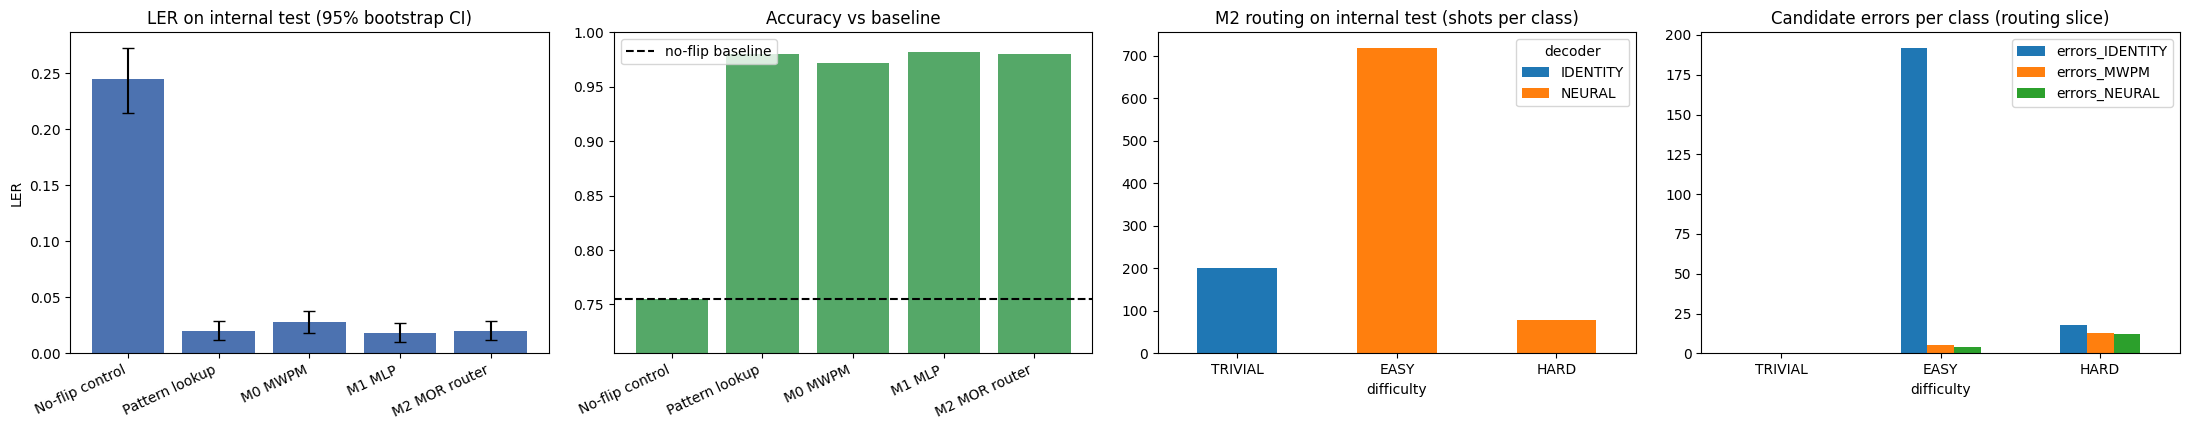

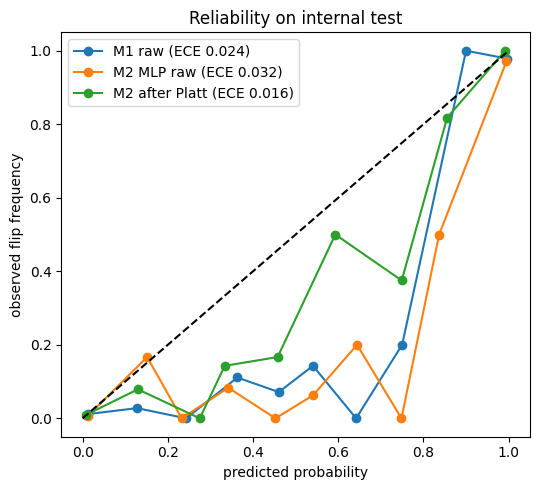

INSIGHTS: LER on 1,000 internal-test shots: No-flip control 0.245; Pattern lookup 0.020; M0 MWPM 0.028; M1 MLP 0.018; M2 MOR router 0.020. No-flip baseline accuracy is 0.755, so a model needs LER below 0.245 to decode anything. 6 of 10 paired comparisons are NOT_STATISTICALLY_RESOLVABLE (interval contains zero). M2 sends 20.2% of internal-test shots to identity or MWPM (no neural network call). 5 internal-test shots have an unseen pattern; ECE on test: M1 raw 0.024, M2 raw 0.032, M2 Platt 0.016.


In [17]:
def counts_to_metrics(tp, fp, fn, tn):
    tp, fp, fn, tn = [np.asarray(a, float) for a in (tp, fp, fn, tn)]
    with np.errstate(divide="ignore", invalid="ignore"):
        n = tp + fp + fn + tn
        LER = (fp + fn) / n; rec = tp / (tp + fn); spec = tn / (tn + fp); prec = tp / (tp + fp)
        f1 = 2 * prec * rec / (prec + rec)
    return dict(LER=LER, accuracy=1 - LER, balanced_accuracy=(rec + spec) / 2, precision=prec, recall=rec, F1=f1)
def point_metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return counts_to_metrics(((y == 1) & (p == 1)).sum(), ((y == 0) & (p == 1)).sum(), ((y == 1) & (p == 0)).sum(), ((y == 0) & (p == 0)).sum())
def boot_metrics(y, p, B):
    yb, pb = np.asarray(y)[B], np.asarray(p)[B]
    return counts_to_metrics(((yb == 1) & (pb == 1)).sum(1), ((yb == 0) & (pb == 1)).sum(1), ((yb == 1) & (pb == 0)).sum(1), ((yb == 0) & (pb == 0)).sum(1))
def ci(a):
    a = np.asarray(a); a = a[~np.isnan(a)]
    return (float(np.percentile(a, 2.5)), float(np.percentile(a, 97.5))) if len(a) else (np.nan, np.nan)
def fmt(v, c):
    return f"{v:.3f} [{c[0]:.3f}, {c[1]:.3f}]"
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (float(c - h), float(c + h))

N_TE = len(y_te)
B1 = np.random.default_rng(SEED).integers(0, N_TE, size=(CONFIG["boot_single"], N_TE))
B2 = np.random.default_rng(SEED + 1).integers(0, N_TE, size=(CONFIG["boot_paired"], N_TE))

m2_te = M2_ROUTER.predict(X_te)
PRED_TE = {"No-flip control": np.zeros(N_TE, int),
           "Pattern lookup": LOOKUP_FULL.predict(X_te)[0],
           "M0 MWPM": mwpm_predict(M0_MATCHER, X_te),
           "M1 MLP": m1_predict(X_te),
           "M2 MOR router": m2_te.predicted_flip.to_numpy()}
rows = []
for name, p in PRED_TE.items():
    pt, bt = point_metrics(y_te, p), boot_metrics(y_te, p, B1)
    cm = [int(((y_te == a) & (p == b)).sum()) for a in (0, 1) for b in (0, 1)]
    rows.append({"method": name, "LER [95% CI]": fmt(pt["LER"], ci(bt["LER"])), "accuracy [95% CI]": fmt(pt["accuracy"], ci(bt["accuracy"])),
                 "no-flip baseline acc": f"{1 - y_te.mean():.3f}", "balanced acc [95% CI]": fmt(pt["balanced_accuracy"], ci(bt["balanced_accuracy"])),
                 "precision": f"{pt['precision']:.3f}" if not np.isnan(pt["precision"]) else "n/a", "recall": f"{pt['recall']:.3f}",
                 "F1 [95% CI]": fmt(pt["F1"], ci(bt["F1"])) if not np.isnan(pt["F1"]) else "n/a", "TN/FP/FN/TP": cm, "_LER": pt["LER"]})
bench = pd.DataFrame(rows)
display(bench.drop(columns="_LER"))
LER_TE = {r["method"]: r["_LER"] for r in rows}

# paired deltas on identical shots
def paired(a, b):
    ea, eb = (PRED_TE[a] != y_te).astype(float), (PRED_TE[b] != y_te).astype(float)
    d = (ea - eb)[B2].mean(1); point = ea.mean() - eb.mean(); lo, hi = ci(d)
    verdict = "NOT_STATISTICALLY_RESOLVABLE" if lo <= 0 <= hi else ("A better (lower LER)" if point < 0 else "A worse (higher LER)")
    return dict(A=a, B=b, delta_LER=point, ci_low=lo, ci_high=hi, verdict=verdict)
pairs = [("Pattern lookup", "No-flip control"), ("M0 MWPM", "No-flip control"), ("M1 MLP", "No-flip control"), ("M2 MOR router", "No-flip control"),
         ("M1 MLP", "M0 MWPM"), ("M2 MOR router", "M0 MWPM"), ("M2 MOR router", "M1 MLP"),
         ("M0 MWPM", "Pattern lookup"), ("M1 MLP", "Pattern lookup"), ("M2 MOR router", "Pattern lookup")]
PAIRED = pd.DataFrame([paired(a, b) for a, b in pairs])
display(PAIRED)

# per-class breakdown
cls_te = m2_te.difficulty.to_numpy()
brk = []
for c in CLASSES:
    m = cls_te == c
    brk.append(dict(difficulty=c, shots=int(m.sum()), flips=int(y_te[m].sum()), **{f"errors {k}": int((v[m] != y_te[m]).sum()) for k, v in PRED_TE.items()}))
BREAKDOWN = pd.DataFrame(brk); display(BREAKDOWN)

# unseen-pattern analysis
seen_te = np.array([int(p) in LOOKUP_FULL.table for p in P_te])
uns = pd.DataFrame([dict(method=k, unseen_shots=int((~seen_te).sum()), errors_on_unseen=int((v[~seen_te] != y_te[~seen_te]).sum()),
                         LER_on_unseen=float(np.mean(v[~seen_te] != y_te[~seen_te])) if (~seen_te).any() else np.nan,
                         errors_on_seen=int((v[seen_te] != y_te[seen_te]).sum())) for k, v in PRED_TE.items()])
display(uns)

# routing shares
route_te = m2_te.groupby(["difficulty", "decoder"]).size().unstack(fill_value=0).reindex(CLASSES).fillna(0).astype(int)
no_nn_share = float((m2_te.decoder != "NEURAL").mean())
display(route_te)

# figures
names = list(PRED_TE); lers = [LER_TE[k] for k in names]
cis = [ci(boot_metrics(y_te, PRED_TE[k], B1)["LER"]) for k in names]
fig, ax = plt.subplots(1, 4, figsize=(22, 4.4))
ax[0].bar(range(len(names)), lers, yerr=[[l - c[0] for l, c in zip(lers, cis)], [c[1] - l for l, c in zip(lers, cis)]], capsize=4, color="#4c72b0")
ax[0].set_xticks(range(len(names))); ax[0].set_xticklabels(names, rotation=25, ha="right"); ax[0].set_title("LER on internal test (95% bootstrap CI)"); ax[0].set_ylabel("LER")
accs = [1 - l for l in lers]
ax[1].bar(range(len(names)), accs, color="#55a868"); ax[1].axhline(1 - y_te.mean(), color="k", ls="--", label="no-flip baseline")
ax[1].set_ylim(min(accs) - 0.05, 1); ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels(names, rotation=25, ha="right"); ax[1].legend(); ax[1].set_title("Accuracy vs baseline")
route_te.plot(kind="bar", stacked=True, ax=ax[2]); ax[2].set_title("M2 routing on internal test (shots per class)"); ax[2].tick_params(axis="x", rotation=0)
re_ = M2_INFO["route_errors"].set_index("difficulty")[[f"errors_{d}" for d in CHEAPNESS]]
re_.plot(kind="bar", ax=ax[3]); ax[3].set_title("Candidate errors per class (routing slice)"); ax[3].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_benchmark.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5))
for lab, p in [("M1 raw", m1_proba(X_te)), ("M2 MLP raw", M2_ROUTER.mlp.predict_proba(X_te)), ("M2 after Platt", M2_ROUTER.calibrate(M2_ROUTER.mlp.predict_proba(X_te)))]:
    r = reliability(p, y_te); ax.plot(r[:, 0], r[:, 1], marker="o", label=f"{lab} (ECE {ece(p, y_te):.3f})")
ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("predicted probability"); ax.set_ylabel("observed flip frequency"); ax.set_title("Reliability on internal test"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_reliability.png", dpi=130); plt.show()
ECE_TE = {lab: ece(p, y_te) for lab, p in [("M1 raw", m1_proba(X_te)), ("M2 raw", M2_ROUTER.mlp.predict_proba(X_te)), ("M2 Platt", M2_ROUTER.calibrate(M2_ROUTER.mlp.predict_proba(X_te)))]}

unres = PAIRED[PAIRED.verdict == "NOT_STATISTICALLY_RESOLVABLE"]
print("INSIGHTS:", "LER on 1,000 internal-test shots: " + "; ".join(f"{k} {v:.3f}" for k, v in LER_TE.items()) + ".",
      f"No-flip baseline accuracy is {1 - y_te.mean():.3f}, so a model needs LER below {y_te.mean():.3f} to decode anything.",
      f"{len(unres)} of {len(PAIRED)} paired comparisons are NOT_STATISTICALLY_RESOLVABLE (interval contains zero).",
      f"M2 sends {no_nn_share:.1%} of internal-test shots to identity or MWPM (no neural network call).",
      f"{int((~seen_te).sum())} internal-test shots have an unseen pattern; ECE on test: " + ", ".join(f"{k} {v:.3f}" for k, v in ECE_TE.items()) + ".")

## 11 Freeze

### Freeze all models, thresholds, routing table and hashes before any final prediction is generated
**Purpose:** Write an immutable record (model files with SHA-256, data hashes, configuration, seeds, slice record ids, routing table, thresholds) so a reviewer can see that the final-test predictions came from frozen models.

**Inputs:** The fitted objects from sections 07 to 09, `DATA_HASHES`, `CONFIG`.

**Method:** Models are saved with `joblib`, hashed, reloaded from disk, and the reloaded copies must reproduce the in-memory internal-test predictions exactly. The manifest is written with a UTC timestamp.

**Expected output:** `outputs/frozen/manifest.json` plus a printed summary and the reload check.

**Interpretation:** Any change to a model after this point changes its hash; the final-prediction cell recomputes the hashes and refuses to run on a mismatch.

**Failure mode:** Refitting anything after seeing internal-test results without relabelling it post-hoc would break the freeze; do not do it.

In [18]:
FROZEN_DIR = OUT_DIR / "frozen"
joblib.dump(dict(model=M1_MODEL, threshold=M1_THR, config=M1_CFG), FROZEN_DIR / "m1.joblib")
joblib.dump(M2_ROUTER, FROZEN_DIR / "m2.joblib")
joblib.dump(LOOKUP_FULL, FROZEN_DIR / "lookup.joblib")
(FROZEN_DIR / "m0.json").write_text(json.dumps(dict(matching_weight_ratio=RATIO_FULL, graph="section 3.7 repetition-code graph"), indent=2))
slices = {k: [int(v) for v in rid_tr[M2_INFO[k]]] for k in ("fit_idx", "val_idx", "route_idx")}
(FROZEN_DIR / "m2_slices_record_ids.json").write_text(json.dumps(slices))
files = ["m1.joblib", "m2.joblib", "lookup.joblib", "m0.json", "m2_slices_record_ids.json"]
manifest = dict(
    frozen_at_utc=dt.datetime.now(dt.timezone.utc).isoformat(), seed=SEED,
    model_files={f: sha256_file(FROZEN_DIR / f) for f in files},
    data_hashes=DATA_HASHES, config=CONFIG,
    m0=dict(ratio=RATIO_FULL), m1=dict(config={k: (list(v) if isinstance(v, tuple) else v) for k, v in M1_CFG.items()}, threshold=M1_THR, epochs=M1_MODEL.epochs, n_params=M1_MODEL.n_params),
    m2=dict(routing=M2_ROUTER.routing, difficulty_thresholds=CONFIG["difficulty"], mwpm_ratio=M2_ROUTER.ratio, platt_a_b=list(M2_ROUTER.platt),
            neural_threshold=M2_ROUTER.thr, slice_sizes={k: len(v) for k, v in slices.items()}),
    versions={k: mods[k].__version__ for k in mods},
)
(FROZEN_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2, default=str))

# reload from disk and verify identical behaviour
m1_back = joblib.load(FROZEN_DIR / "m1.joblib"); m2_back = joblib.load(FROZEN_DIR / "m2.joblib"); lk_back = joblib.load(FROZEN_DIR / "lookup.joblib")
same_m1 = np.array_equal((m1_back["model"].predict_proba(X_te) >= m1_back["threshold"]).astype(int), PRED_TE["M1 MLP"])
same_m2 = np.array_equal(m2_back.predict(X_te).predicted_flip.to_numpy(), PRED_TE["M2 MOR router"])
same_lk = np.array_equal(lk_back.predict(X_te)[0], PRED_TE["Pattern lookup"])
assert same_m1 and same_m2 and same_lk
FROZEN = True
display(pd.Series(manifest["model_files"], name="sha256").to_frame())
print("Frozen at (UTC):", manifest["frozen_at_utc"])
print("\nINSIGHTS:", f"{len(files)} files frozen and hashed; reloaded M1, M2 and the lookup control reproduce the in-memory internal-test predictions exactly ({same_m1}, {same_m2}, {same_lk}). The final-test predictions are generated only after this point.")

,sha256
m1.joblib,e9f23ef66d058f0a9f895fdbe22edd980c77f238201700...
m2.joblib,87723f087efe867c3501d9d90db4dbb0f4c76147588fff...
lookup.joblib,94d454b42b8eef79af89cf26d1803aeb4058c7fd335b68...
m0.json,38def7a5c058d4480d949e31da1bdea243d1f16f8b8ac6...
m2_slices_record_ids.json,d7a82a0807dce7591c4cca0c64f713bbe0d1366da1cf05...


Frozen at (UTC): 2026-10-26T12:14:35.857901+00:00

INSIGHTS: 5 files frozen and hashed; reloaded M1, M2 and the lookup control reproduce the in-memory internal-test predictions exactly (True, True, True). The final-test predictions are generated only after this point.


## 12 Final predictions (no scoring)

### Write the prediction CSVs for the final test from the frozen models
**Purpose:** Produce `predictions_final_test_M0.csv`, `_M1.csv`, `_M2.csv` (and the internal-test equivalents) and hash them. The final test has no labels, so nothing is scored here.

**Inputs:** `final_test_inputs.parquet` (detector bits only) and the frozen model files re-loaded from disk after their hashes are re-verified.

**Method:** Columns: `record_id`, `predicted_flip` (0/1), `p_flip` (M1: raw MLP probability; M2: calibrated probability where the neural decoder ran, else NaN; M0: NaN because matching has no probability).

**Expected output:** Six CSV files, a validation table (row count, id set, value ranges) and a drift summary between internal and final test (inputs and predicted rates only).

**Interpretation:** A difference between internal and final test predicted-flip rates or routing shares is a drift observation about the later hardware job, not a quality score.

**Failure mode:** Using the labels of the final test is impossible by construction (the file has none) and the notebook never tries to recover them.

In [19]:
assert FROZEN and (FROZEN_DIR / "manifest.json").exists(), "Freeze first"
man = json.loads((FROZEN_DIR / "manifest.json").read_text())
for f, h in man["model_files"].items():
    assert sha256_file(FROZEN_DIR / f) == h, f"Frozen file changed after the freeze: {f}"
m1_f = joblib.load(FROZEN_DIR / "m1.joblib"); m2_f = joblib.load(FROZEN_DIR / "m2.joblib")
m0_matcher_f = build_matching(json.loads((FROZEN_DIR / "m0.json").read_text())["matching_weight_ratio"])

def predict_all(X, rid):
    X = guard_inputs(X)
    p1 = m1_f["model"].predict_proba(X)
    m2 = m2_f.predict(X)
    return {"M0": pd.DataFrame(dict(record_id=rid, predicted_flip=mwpm_predict(m0_matcher_f, X), p_flip=np.nan)),
            "M1": pd.DataFrame(dict(record_id=rid, predicted_flip=(p1 >= m1_f["threshold"]).astype(int), p_flip=p1)),
            "M2": pd.DataFrame(dict(record_id=rid, predicted_flip=m2.predicted_flip.to_numpy(), p_flip=m2.p_cal.to_numpy()))}, m2

final_preds, m2_fi = predict_all(X_fi, rid_fi)
internal_preds, _ = predict_all(X_te, rid_te)
written, rows = {}, []
for tag, preds, n_exp, ids_exp in [("final_test", final_preds, 2000, set(rid_fi.tolist())), ("internal_test", internal_preds, len(rid_te), set(rid_te.tolist()))]:
    for m, df in preds.items():
        path = OUT_DIR / f"predictions_{tag}_{m}.csv"
        df.to_csv(path, index=False)
        chk = pd.read_csv(path)
        ok = (len(chk) == n_exp and set(chk.record_id) == ids_exp and list(chk.columns) == ["record_id", "predicted_flip", "p_flip"]
              and set(chk.predicted_flip.unique()) <= {0, 1} and chk.p_flip.dropna().between(0, 1).all())
        assert ok, f"validation failed for {path.name}"
        written[path.name] = sha256_file(path)
        rows.append(dict(file=path.name, rows=len(chk), predicted_flip_rate=chk.predicted_flip.mean(), p_flip_nan_share=chk.p_flip.isna().mean(), valid="OK", sha256=written[path.name][:16] + "..."))
display(pd.DataFrame(rows))
(OUT_DIR / "final_predictions_manifest.json").write_text(json.dumps(dict(written_after_freeze=man["frozen_at_utc"], files=written), indent=2))

drift = pd.DataFrame({
    "internal_test": [X_te.sum(1).mean(), internal_preds["M0"].predicted_flip.mean(), internal_preds["M1"].predicted_flip.mean(), internal_preds["M2"].predicted_flip.mean(), (m2_te.decoder != "NEURAL").mean()],
    "final_test": [X_fi.sum(1).mean(), final_preds["M0"].predicted_flip.mean(), final_preds["M1"].predicted_flip.mean(), final_preds["M2"].predicted_flip.mean(), (m2_fi.decoder != "NEURAL").mean()]},
    index=["mean detector weight", "M0 predicted flip rate", "M1 predicted flip rate", "M2 predicted flip rate", "M2 share without neural call"])
display(drift)
print("INSIGHTS:", f"6 prediction files written after the freeze (final test: 2,000 rows each) and validated. The predicted flip rate of M2 moves from {drift.loc['M2 predicted flip rate', 'internal_test']:.3f} (internal) to "
      f"{drift.loc['M2 predicted flip rate', 'final_test']:.3f} (final), and mean detector weight from {drift.loc['mean detector weight', 'internal_test']:.2f} to {drift.loc['mean detector weight', 'final_test']:.2f}: "
      "this is a drift observation of the later job (the final test has no labels, so it is not a score).")

,file,rows,predicted_flip_rate,p_flip_nan_share,valid,sha256
0,predictions_final_test_M0.csv,2000,0.2600,1.0000,OK,618122df07f32d2b...
1,predictions_final_test_M1.csv,2000,0.2495,0.0000,OK,ffaf811b61fcb1d2...
2,predictions_final_test_M2.csv,2000,0.2530,0.1995,OK,55d7b0d1b46cbf41...
3,predictions_internal_test_M0.csv,1000,0.2530,1.0000,OK,0354bbe357fd65e8...
4,predictions_internal_test_M1.csv,1000,0.2370,0.0000,OK,c30a3c47589fc654...
5,predictions_internal_test_M2.csv,1000,0.2410,0.2020,OK,5f0172a77cf4d6d2...


,internal_test,final_test
mean detector weight,1.278,1.2635
M0 predicted flip rate,0.253,0.2600
M1 predicted flip rate,0.237,0.2495
M2 predicted flip rate,0.241,0.2530
M2 share without neural call,0.202,0.1995


INSIGHTS: 6 prediction files written after the freeze (final test: 2,000 rows each) and validated. The predicted flip rate of M2 moves from 0.241 (internal) to 0.253 (final), and mean detector weight from 1.28 to 1.26: this is a drift observation of the later job (the final test has no labels, so it is not a score).


## 13 Hardware access (real IBM backend, budget guard, ledger)

### Authenticate, choose a real dynamic-circuit backend, pick the qubit line, set up the budget guard and the append-only ledger
**Purpose:** Open the IBM Quantum service with credentials from the environment, choose a real (non-simulator) backend that supports `if_else`, choose the best five-qubit line, report the remaining QPU time and prepare job recovery.

**Inputs:** `QISKIT_IBM_TOKEN`, `QISKIT_IBM_INSTANCE`, `QISKIT_IBM_CHANNEL` (environment). Optional `QDECODE_BACKEND` to force a backend name, `QDECODE_SUBMIT=0` to forbid submissions.

**Method:** `QiskitRuntimeService()` is created with **no arguments** so it reads the environment. Candidate backends: `simulator=False`, `operational=True`, at least 5 qubits, `if_else` in `operation_names`; the least busy one is used unless a name is forced. The physical line $p_0\!-\!p_1\!-\!p_2\!-\!p_3\!-\!p_4$ (roles data0, anc0, data1, anc1, data2) minimises $\sum_{q\in line}\epsilon_{\text{readout}}(q)+\sum_{edges}\epsilon_{2q}$ taken from the backend target. Budget guard: refuse a batch if $\text{planned}+\text{reserve}>\text{remaining}$; unknown usage is `None`, never 0.

**Expected output:** A candidate-backend table, the chosen backend and layout, remaining QPU seconds, and the status `OK` or a `BLOCKED_*` flag.

**Interpretation:** A non-simulator backend with `if_else` is required for the active circuit. The layout record is stored with every job.

**Failure mode:** No credentials, no dynamic-circuit backend or no quota gives `BLOCKED_*`: the hardware sections then stop and say so; nothing is faked.

In [20]:

# Reload credentials without displaying their values.
for cand in (REPO_ROOT / ".env", SRC_DIR / ".env"):
    load_env_file(cand)

os.environ.setdefault(
    "QISKIT_IBM_CHANNEL",
    "ibm_quantum_platform"
)

print("Token present:", bool(os.environ.get("QISKIT_IBM_TOKEN")))
print("Instance present:", bool(os.environ.get("QISKIT_IBM_INSTANCE")))
print("Channel:", os.environ.get("QISKIT_IBM_CHANNEL"))


Token present: True
Instance present: True
Channel: ibm_quantum_platform


In [ ]:

from qiskit_ibm_runtime import QiskitRuntimeService

try:
    service = QiskitRuntimeService()
    print("Authentication successful.")
    print("Available instance usage:", service.usage())
except Exception as e:
    print("Authentication failed:", type(e).__name__)
    print(str(e)[:300])


In [24]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

HW = dict(status="NOT_STARTED", reason="", service=None, backend=None, usage=None, layout=None, initial_layout=None, roles=None)
LEDGER = OUT_DIR / "qpu_ledger.jsonl"

def ledger_append(**kw):
    rec = dict(ts_utc=dt.datetime.now(dt.timezone.utc).isoformat(), **kw)
    with open(LEDGER, "a", encoding="utf-8") as fh:
        fh.write(json.dumps(rec, default=str) + "\n")
def ledger_events():
    return [json.loads(l) for l in LEDGER.read_text().splitlines() if l.strip()] if LEDGER.exists() else []
def ledger_latest():
    merged = {}
    for e in ledger_events():
        if "job_id" not in e:
            continue
        cur = merged.setdefault(e["job_id"], {})
        for k, v in e.items():
            if v is not None or k not in cur:
                cur[k] = v
    return merged

def parse_remaining(usage):
    if not isinstance(usage, dict):
        return None
    for k, v in usage.items():
        if "remaining" in k.lower() and isinstance(v, (int, float)):
            return float(v)
    lim = next((v for k, v in usage.items() if "limit" in k.lower() and isinstance(v, (int, float))), None)
    used = next((v for k, v in usage.items() if "consumed" in k.lower() and isinstance(v, (int, float))), None)
    return float(lim - used) if lim is not None and used is not None else None

def remaining_qpu():
    try:
        rem = parse_remaining(HW["service"].usage())
        if rem is not None:
            return rem, "IBM service.usage()"
    except Exception:
        pass
    known = sum(e["qpu_seconds"] for e in ledger_latest().values() if e.get("qpu_seconds") is not None)
    return CONFIG["qpu_budget_s"] - known, "estimated: configured budget minus ledger (IBM usage unavailable)"

def budget_guard(planned_s, stage):
    rem, src = remaining_qpu()
    ok = planned_s + CONFIG["qpu_reserve_s"] <= rem
    print(f"[budget guard] stage={stage}: planned {planned_s:.1f}s + reserve {CONFIG['qpu_reserve_s']}s vs remaining {rem:.1f}s ({src}) -> {'OK' if ok else 'BUDGET_EXHAUSTED'}")
    return ok

def connect_and_select():
    try:
        svc = QiskitRuntimeService()
    except Exception as e:
        return "BLOCKED_IBM_ACCESS", f"{type(e).__name__}: {redact(e)[:220]}"
    HW["service"] = svc
    try:
        HW["usage"] = svc.usage()
    except Exception as e:
        return "BLOCKED_IBM_ACCESS", f"service.usage() failed: {type(e).__name__}: {redact(e)[:200]}"
    cands = svc.backends(simulator=False, operational=True, min_num_qubits=5)
    rows = []
    for b in cands:
        try:
            pend = b.status().pending_jobs
        except Exception:
            pend = None
        rows.append(dict(backend=b.name, qubits=b.num_qubits, pending_jobs=pend, dynamic_circuits=("if_else" in b.operation_names), _b=b))
    tab = pd.DataFrame(rows)
    if tab.empty:
        return "BLOCKED_NO_BACKEND", "no operational real backend with at least 5 qubits"
    display(tab.drop(columns="_b"))
    dyn = tab[tab.dynamic_circuits]
    if CONFIG["backend_name"]:
        pick = tab[tab.backend == CONFIG["backend_name"]]
        if pick.empty:
            return "BLOCKED_NO_BACKEND", f"forced backend {CONFIG['backend_name']} is not available to this account"
    else:
        if dyn.empty:
            return "BLOCKED_NO_DYNAMIC_BACKEND", "no available backend lists if_else in operation_names"
        pick = dyn.sort_values("pending_jobs", na_position="last").head(1)
    b = pick.iloc[0]._b
    if "if_else" not in b.operation_names:
        return "BLOCKED_NO_DYNAMIC_BACKEND", f"{b.name} does not support if_else"
    real_names = {x.name for x in svc.backends(simulator=False)}
    assert b.name in real_names and not getattr(b, "simulator", False), "Chosen backend must be a real device"
    HW["backend"] = b
    return "OK", f"{b.name}"

def two_qubit_error_map(target):
    skip = {"if_else", "while_loop", "for_loop", "switch_case", "delay", "barrier", "measure", "reset"}
    em = {}
    for op, qargs in target.instructions:
        if qargs is None or len(qargs) != 2 or getattr(op, "name", None) in skip:
            continue
        err = target[op.name][qargs].error
        if err is not None:
            em[frozenset(qargs)] = min(err, em.get(frozenset(qargs), 1.0))
    return em

def choose_line(backend):
    target = backend.target
    meas = {q[0]: p.error for q, p in target["measure"].items() if q is not None and p is not None and p.error is not None}
    em = two_qubit_error_map(target)
    adj = {}
    for a, b in backend.coupling_map.get_edges():
        adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
    paths = []
    def dfs(path):
        if len(path) == 5:
            if path[0] < path[-1]:
                paths.append(tuple(path))
            return
        for nb in adj[path[-1]]:
            if nb not in path:
                dfs(path + [nb])
    for s in adj:
        dfs([s])
    scored = []
    for p in paths:
        r = [meas.get(q) for q in p]; e = [em.get(frozenset((p[i], p[i + 1]))) for i in range(4)]
        if any(v is None for v in r + e):
            continue
        scored.append((float(sum(r) + sum(e)), p, float(sum(r)), float(sum(e))))
    scored.sort()
    return scored

HW["status"], HW["reason"] = connect_and_select()
if HW["status"] == "OK":
    scored = choose_line(HW["backend"])
    best_score, line, r_sum, e_sum = scored[0]
    HW["layout"] = line
    HW["roles"] = dict(data0=line[0], anc0=line[1], data1=line[2], anc1=line[3], data2=line[4])
    HW["initial_layout"] = [line[0], line[2], line[4], line[1], line[3]]   # order of circuit qubits: data0, data1, data2, anc0, anc1
    display(pd.DataFrame([dict(rank=i + 1, line=s[1], score=s[0], readout_err_sum=s[2], two_qubit_err_sum=s[3]) for i, s in enumerate(scored[:5])]))
    rem, src = remaining_qpu()
    rec = dict(backend=HW["backend"].name, num_qubits=HW["backend"].num_qubits, line=list(line), roles=HW["roles"], remaining_qpu_s=rem, remaining_source=src,
               usage_snapshot=HW["usage"], recorded_utc=dt.datetime.now(dt.timezone.utc).isoformat())
    (OUT_DIR / "backend_record.json").write_text(json.dumps(rec, indent=2, default=str))
    print(f"STATUS OK | backend {HW['backend'].name} (real device, if_else supported) | line {line} | roles {HW['roles']}")
    print(f"Remaining QPU time: {rem:.1f} s ({src})")
    print("\nINSIGHTS:", f"{HW['backend'].name} is a real backend with dynamic circuits; the best of {len(scored)} candidate lines has summed readout error {r_sum:.3f} and summed two-qubit error {e_sum:.3f}. "
          f"{rem:.0f} s of QPU time remain against a plan that needs well under {CONFIG['qpu_calibration_cap_s'] + CONFIG['qpu_partA_cap_s']} s plus a {CONFIG['qpu_reserve_s']} s reserve.")
else:
    print("STATUS", HW["status"], "|", HW["reason"])
    print("\nINSIGHTS:", f"Hardware phases are {HW['status']}. The classical results above are complete and valid; Part A cannot be run until access is fixed. No data were faked or simulated to fill the gap.")

,backend,qubits,pending_jobs,dynamic_circuits
0,ibm_fez,156,0,True
1,ibm_kingston,156,35,True
2,ibm_marrakesh,156,1998,True


,rank,line,score,readout_err_sum,two_qubit_err_sum
0,1,"(22, 23, 24, 25, 26)",0.041715,0.031250,0.010465
1,2,"(143, 144, 145, 146, 147)",0.042485,0.032227,0.010258
2,3,"(142, 143, 144, 145, 146)",0.042982,0.032837,0.010145
3,4,"(20, 21, 22, 23, 24)",0.043203,0.031982,0.011221
4,5,"(137, 147, 146, 145, 144)",0.043295,0.033569,0.009725


STATUS OK | backend ibm_fez (real device, if_else supported) | line (22, 23, 24, 25, 26) | roles {'data0': 22, 'anc0': 23, 'data1': 24, 'anc1': 25, 'data2': 26}
Remaining QPU time: 590.0 s (IBM service.usage())

INSIGHTS: ibm_fez is a real backend with dynamic circuits; the best of 428 candidate lines has summed readout error 0.031 and summed two-qubit error 0.010. 590 s of QPU time remain against a plan that needs well under 70 s plus a 130 s reserve.


## 14 Circuits before submission (BEFORE = passive, AFTER = active)

### Create the 16 memory circuits in code, print and draw them, transpile for the real backend, record metrics and save QPY
**Purpose:** Build the passive (BEFORE) and active (AFTER) repetition-code memory circuits for the 8 configurations, show them, and produce the evidence the judges need before any job is submitted.

**Inputs:** `build_memory_circuit(active, prepared_bit, inj_qubit, inj_round)`; the layout from section 13; optimisation level 1, fixed `seed_transpiler`.

**Method:** Registers: data (3), ancilla (2), classical `syn0`,`syn1`,`syn2` (2 bits each) and `final` (3 bits). Per round: reset ancillas, $CX(d_i\to a_i)$ and $CX(d_{i+1}\to a_i)$, measure into `syn r`. A deliberate $X$ on a data qubit is placed after the chosen round. Active version: before the final readout, if `syn2`$=01$ flip data0, $=11$ flip data1, $=10$ flip data2. Qubit order for the layout: data0, data1, data2, anc0, anc1.

**Expected output:** Text diagrams of the logical and transpiled circuits (data qubit 1 fault after round 0), figures in `outputs/figures/`, a metrics table (depth, size, two-qubit gates, mid-circuit measurements, resets, conditional blocks, layout, circuit hash) and QPY files.

**Interpretation:** The only structural difference between BEFORE and AFTER is the three `if` blocks driven by the last syndrome register; the table shows what that costs in depth.

**Failure mode:** If the transpiled circuit uses qubits outside the chosen line (routing swaps) the layout column shows it; the check below reports that.

In [25]:
from io import BytesIO
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, qpy
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

def build_memory_circuit(active, prepared_bit=0, inj_qubit=None, inj_round=None, name=None):
    data, anc = QuantumRegister(3, "data"), QuantumRegister(2, "anc")
    syn = [ClassicalRegister(2, f"syn{r}") for r in range(3)]
    fin = ClassicalRegister(3, "final")
    qc = QuantumCircuit(data, anc, *syn, fin, name=name)
    if prepared_bit:
        qc.x(data)
    qc.barrier()
    for r in range(3):
        qc.reset(anc)
        for i in range(2):
            qc.cx(data[i], anc[i]); qc.cx(data[i + 1], anc[i])
        qc.measure(anc, syn[r])
        qc.barrier()
        if inj_qubit is not None and inj_round == r:
            qc.x(data[inj_qubit]); qc.barrier()
    if active:
        for value, q in ((0b01, 0), (0b11, 1), (0b10, 2)):
            with qc.if_test((syn[2], value)):
                qc.x(data[q])
    qc.measure(data, fin)
    return qc

PARTA_CONFIGS = [("natural_b0", 0, None, None), ("natural_b1", 1, None, None)] + [(f"xq{q}_after{r}", 0, q, r) for q in range(3) for r in range(2)]
LOGICAL, ORDER = {}, []
for cname, bit, q, r in PARTA_CONFIGS:
    for ver in ("passive", "active"):          # interleaved: passive then active for every configuration
        LOGICAL[(cname, ver)] = build_memory_circuit(ver == "active", bit, q, r, name=f"rep_d3_r3_b{bit}_{ver}_{cname}")
        ORDER.append((cname, ver))
PREP = {c[0]: c[1] for c in PARTA_CONFIGS}
assert len(LOGICAL) == 16

show = ("xq1_after0",)
for ver in ("passive", "active"):
    print(f"===== LOGICAL circuit: {ver.upper()} ({'BEFORE' if ver == 'passive' else 'AFTER'}), data qubit 1 fault after round 0 =====")
    print(LOGICAL[("xq1_after0", ver)].draw("text", fold=170))
    try:
        fig = LOGICAL[("xq1_after0", ver)].draw("mpl", fold=40)
        fig.savefig(FIG_DIR / f"qec_{'before_passive' if ver == 'passive' else 'after_active'}_logical.png", dpi=130, bbox_inches="tight"); plt.close(fig)
    except Exception as e:
        print("(mpl drawing skipped:", type(e).__name__, ")")

def qpy_hash(circ):
    buf = BytesIO(); qpy.dump(circ, buf); return hashlib.sha256(buf.getvalue()).hexdigest()[:16]
def circuit_row(circ, layout_txt, tag):
    ops = circ.count_ops()
    twoq = sum(v for k, v in ops.items() if k in ("cx", "cz", "ecr", "swap"))
    return dict(circuit=tag, depth=circ.depth(), size=circ.size(), two_qubit_gates=twoq, mid_circuit_measure=ops.get("measure", 0) - 3,
                resets=ops.get("reset", 0), conditional_blocks=ops.get("if_else", 0), layout=layout_txt, hash=qpy_hash(circ))

rows = [circuit_row(LOGICAL[k], "logical", f"{k[1]} / {k[0]}") for k in ORDER if k[0] == "xq1_after0" or k[0] == "natural_b0"]
ISA = {}
if HW["status"] == "OK":
    pm = generate_preset_pass_manager(optimization_level=CONFIG["transpile_optimization_level"], backend=HW["backend"],
                                      initial_layout=HW["initial_layout"], seed_transpiler=SEED)
    for k in ORDER:
        ISA[k] = pm.run(LOGICAL[k])
    layout_set = set(HW["layout"])
    used = {k: {ISA[k].find_bit(q).index for inst in ISA[k].data for q in inst.qubits if inst.operation.name != "barrier"} for k in ORDER}
    stray = {k: sorted(v - layout_set) for k, v in used.items() if v - layout_set}
    rows += [circuit_row(ISA[k], f"phys {sorted(HW['layout'])}", f"{k[1]} / {k[0]} (transpiled)") for k in ORDER if k[0] in ("xq1_after0", "natural_b0")]
    for ver in ("passive", "active"):
        print(f"===== TRANSPILED circuit: {ver.upper()}, data qubit 1 fault after round 0, physical qubits {HW['roles']} =====")
        print(ISA[("xq1_after0", ver)].draw("text", idle_wires=False, fold=170))
        try:
            fig = ISA[("xq1_after0", ver)].draw("mpl", idle_wires=False, fold=40)
            fig.savefig(FIG_DIR / f"qec_{ver}_transpiled.png", dpi=130, bbox_inches="tight"); plt.close(fig)
        except Exception as e:
            print("(mpl drawing of transpiled circuit skipped:", type(e).__name__, ")")
    with open(OUT_DIR / "qpy" / "partA_submitted_isa_circuits.qpy", "wb") as fh:
        qpy.dump([ISA[k] for k in ORDER], fh)
    (OUT_DIR / "qpy" / "partA_submitted_order.json").write_text(json.dumps([list(k) for k in ORDER]))
with open(OUT_DIR / "qpy" / "partA_logical_circuits.qpy", "wb") as fh:
    qpy.dump([LOGICAL[k] for k in ORDER], fh)
METRICS = pd.DataFrame(rows)
display(METRICS)
METRICS.to_csv(OUT_DIR / "partA_circuit_metrics.csv", index=False)
if HW["status"] == "OK":
    pa, ac = METRICS[METRICS.circuit == "passive / xq1_after0 (transpiled)"].iloc[0], METRICS[METRICS.circuit == "active / xq1_after0 (transpiled)"].iloc[0]
    print("INSIGHTS:", f"Transpiled to {HW['backend'].name}, the passive circuit has depth {pa.depth} and {pa.two_qubit_gates} two-qubit gates; the active circuit has depth {ac.depth} with {ac.conditional_blocks} conditional blocks "
          f"(+{ac.depth - pa.depth} depth). Qubits outside the chosen line used by any circuit: {len(stray)}. All 16 circuits and their QPY files are saved before submission.")
else:
    print("INSIGHTS:", "Logical circuits were built, printed and saved (QPY). Transpilation needs a backend, so it is BLOCKED together with section 13; the logical depth/size above is what the transpiler would start from.")

===== LOGICAL circuit: PASSIVE (BEFORE), data qubit 1 fault after round 0 =====
          ░                                 ░       ░                                 ░                                 ░ ┌─┐      
 data_0: ─░────────■────────────────────────░───────░────────■────────────────────────░────────■────────────────────────░─┤M├──────
          ░        │                        ░ ┌───┐ ░        │                        ░        │                        ░ └╥┘┌─┐   
 data_1: ─░────────┼────■────■──────────────░─┤ X ├─░────────┼────■────■──────────────░────────┼────■────■──────────────░──╫─┤M├───
          ░        │    │    │              ░ └───┘ ░        │    │    │              ░        │    │    │              ░  ║ └╥┘┌─┐
 data_2: ─░────────┼────┼────┼───────■──────░───────░────────┼────┼────┼───────■──────░────────┼────┼────┼───────■──────░──╫──╫─┤M├
          ░      ┌─┴─┐┌─┴─┐  │  ┌─┐  │      ░       ░      ┌─┴─┐┌─┴─┐  │  ┌─┐  │      ░      ┌─┴─┐┌─┴─┐  │  ┌─┐  │      ░  ║  ║ 

,circuit,depth,size,two_qubit_gates,mid_circuit_measure,resets,conditional_blocks,layout,hash
0,passive / natural_b0,19,27,12,6,6,0,logical,dd2385ccf9e18d30
1,active / natural_b0,22,30,12,6,6,3,logical,7f998046fb462275
2,passive / xq1_after0,20,28,12,6,6,0,logical,ec01f5c1079cb1ff
3,active / xq1_after0,23,31,12,6,6,3,logical,cae48bed6416db45
4,passive / natural_b0 (transpiled),37,63,12,6,6,0,"phys [22, 23, 24, 25, 26]",746aa09eb258eb67
5,active / natural_b0 (transpiled),40,66,12,6,6,3,"phys [22, 23, 24, 25, 26]",e14b38f918874bfd
6,passive / xq1_after0 (transpiled),38,64,12,6,6,0,"phys [22, 23, 24, 25, 26]",f71a8c9cdcdfa31e
7,active / xq1_after0 (transpiled),41,67,12,6,6,3,"phys [22, 23, 24, 25, 26]",76bf1e9224fbb7aa


INSIGHTS: Transpiled to ibm_fez, the passive circuit has depth 38 and 12 two-qubit gates; the active circuit has depth 41 with 3 conditional blocks (+3 depth). Qubits outside the chosen line used by any circuit: 0. All 16 circuits and their QPY files are saved before submission.


## 15 Calibration job (tiny) and plan

### Run a tiny real-hardware job to measure the cost per circuit and recompute the plan
**Purpose:** Find out what a job costs in QPU seconds before spending the Part A budget, and confirm that the plan fits with the reserve.

**Inputs:** 4 circuits (natural and data-qubit-1 fault, each passive and active) at 100 shots, the ISA circuits of section 14.

**Method:** The job's reported quantum seconds $c_{cal}$ include the fixed job overhead, so a conservative upper bound for Part A is $\hat c_{A}=c_{cal}\cdot\frac{16\cdot 250}{4\cdot 100}$. The budget guard needs $\hat c_A+\text{reserve}\le\text{remaining}$. Job id is saved to the ledger **immediately** after submission; re-running this cell recovers the same job with `service.job(job_id)` instead of resubmitting.

**Expected output:** Job id, backend, shots, QPU seconds and the recomputed plan.

**Interpretation:** A cheap job first protects the budget; the printed bound is deliberately pessimistic.

**Failure mode:** A cancelled or failed job is reported and Part A is not started on a plan that does not fit.

In [26]:
def job_qpu_seconds(job):
    for getter in (lambda: job.usage(), lambda: job.metrics()["usage"]["quantum_seconds"]):
        try:
            v = getter()
            if v is not None:
                return float(v)
        except Exception:
            continue
    return None

def run_or_recover(stage, names, circuits, shots, planned_s):
    """Submit one job (or recover the one already in the ledger for this stage). Returns (job, names, recovered)."""
    prev = [e for e in ledger_latest().values() if e.get("stage") == stage and e.get("status_final") not in ("ERROR", "CANCELLED")]
    if prev:
        e = prev[-1]
        print(f"[{stage}] recovering existing job {e['job_id']} from the ledger (no resubmission)")
        return HW["service"].job(e["job_id"]), e["circuit_names"], True
    if not CONFIG["submit_to_qpu"]:
        raise RuntimeError("BLOCKED_SUBMISSION_DISABLED: QDECODE_SUBMIT=0 and no job in the ledger")
    if not budget_guard(planned_s, stage):
        raise RuntimeError("BUDGET_EXHAUSTED")
    sampler = SamplerV2(mode=HW["backend"])
    job = sampler.run(circuits, shots=shots)
    ledger_append(job_id=job.job_id(), stage=stage, backend=HW["backend"].name, shots=shots, n_circuits=len(circuits), circuit_names=names,
                  circuit_hashes=[qpy_hash(c) for c in circuits], layout=HW["roles"], qpu_seconds=None, status_final=None,
                  qpy_file="qpy/partA_submitted_isa_circuits.qpy")
    print(f"[{stage}] submitted job {job.job_id()} on {HW['backend'].name}; waiting for the result (queue time is not QPU time)...")
    return job, names, False

CAL = dict(status="NOT_RUN")
if HW["status"] != "OK":
    CAL["status"] = HW["status"]
    print("Calibration:", CAL["status"], "- skipped.")
else:
    cal_keys = [("natural_b0", "passive"), ("natural_b0", "active"), ("xq1_after0", "passive"), ("xq1_after0", "active")]
    cal_names = [f"{c}|{v}" for c, v in cal_keys]
    try:
        job, names_back, recovered = run_or_recover("calibration", cal_names, [ISA[k] for k in cal_keys], CONFIG["shots_calibration"], CONFIG["qpu_calibration_cap_s"])
        res = job.result()
        sec = job_qpu_seconds(job)
        ledger_append(job_id=job.job_id(), stage="calibration", qpu_seconds=sec, status_final="DONE")
        n_ret = [len(res[i].data.final.get_bitstrings()) for i in range(len(res))]
        plan_upper = None if sec is None else sec * (16 * CONFIG["shots_partA"]) / (4 * CONFIG["shots_calibration"])
        CAL = dict(status="OK", job_id=job.job_id(), qpu_seconds=sec, shots_returned=n_ret, plan_upper_bound_s=plan_upper, recovered=recovered)
        display(pd.Series(CAL, name="calibration").to_frame())
        print("INSIGHTS:", f"Calibration job {job.job_id()} returned {n_ret} shots for 4 circuits and used "
              + (f"{sec:.1f} QPU seconds, so the pessimistic Part A bound is {plan_upper:.0f} s (suggested cap {CONFIG['qpu_partA_cap_s']} s; the bound includes the job overhead several times over)." if sec is not None else "an unknown number of QPU seconds (IBM did not report it; recorded as None, not 0)."))
    except RuntimeError as e:
        CAL = dict(status=str(e).split(":")[0])
        print("Calibration:", e)

[budget guard] stage=calibration: planned 30.0s + reserve 130s vs remaining 590.0s (IBM service.usage()) -> OK
[calibration] submitted job dbfka8fgdj9s73bbr170 on ibm_fez; waiting for the result (queue time is not QPU time)...


,calibration
status,OK
job_id,dbfka8fgdj9s73bbr170
qpu_seconds,2.0
shots_returned,"[100, 100, 100, 100]"
plan_upper_bound_s,20.0
recovered,False


INSIGHTS: Calibration job dbfka8fgdj9s73bbr170 returned [100, 100, 100, 100] shots for 4 circuits and used 2.0 QPU seconds, so the pessimistic Part A bound is 20 s (suggested cap 40 s; the bound includes the job overhead several times over).


## 16 Part A: passive vs active memory on real hardware, shot-aligned

### Run all 16 circuits interleaved in ONE job, parse per-shot bitstrings, form detectors and compare BEFORE (passive) with AFTER (active)
**Purpose:** Answer: does correcting inside the quantum program change the logical error compared with decoding offline?

**Inputs:** The 16 ISA circuits (passive/active alternating per configuration), 250 shots each, frozen M0/M1/M2 for the offline decoders.

**Method:** Each register is read with `data.<register>.get_bitstrings()` so syndrome rounds and the final readout stay paired by shot; bit $k$ of a string is `s[-1-k]`. Detectors follow section 03. For the **active** circuit the commanded flips (a function of `syn2` only) are XOR-ed out of the final readout before forming the last detector layer; the measured `final` register itself defines the label. Label: $\text{obs}=f_0\oplus b_{init}$. Intervals: Wilson for single proportions; unpaired bootstrap for passive-versus-active differences (different shots, same job).

**Expected output:** Per-configuration and pooled tables (raw, passive plus offline decoders, active, commanded-correction share) with intervals, a chart and a raw per-shot CSV.

**Interpretation:** Passive and active are compared only inside this one job. The active circuit corrects only from the last syndrome, so it can fix a single data-qubit flip seen in that syndrome but not noise that appears after the last round (readout errors, relaxation).

**Failure mode:** If the job is cancelled or a register is missing, results are not used; shots returned must equal shots requested.

[budget guard] stage=partA: planned 20.0s + reserve 130s vs remaining 588.0s (IBM service.usage()) -> OK
[partA] submitted job dbfkb9vpc3tc739nlkeg on ibm_fez; waiting for the result (queue time is not QPU time)...
Part A job: {'status': 'OK', 'job_id': 'dbfkb9vpc3tc739nlkeg', 'qpu_seconds': 3.0, 'backend': 'ibm_fez', 'recovered': False}


,config,n_passive,passive_raw_LER,passive+M0_LER,passive+M1_LER,passive+M2_LER,n_active,active_before_feedback_LER,active_LER,commanded_share
0,natural_b0,250,0.000,0.000,0.000,0.000,250,0.004,0.040,0.060
1,natural_b1,250,0.120,0.032,0.020,0.024,250,0.096,0.064,0.272
2,xq0_after0,250,0.932,0.012,0.044,0.032,250,0.944,0.100,0.936
3,xq0_after1,250,0.968,0.008,0.048,0.048,250,0.972,0.080,0.960
4,xq1_after0,250,0.004,0.024,0.012,0.020,250,0.008,0.044,0.932
5,xq1_after1,250,0.004,0.036,0.048,0.052,250,0.000,0.048,0.976
6,xq2_after0,250,0.000,0.012,0.000,0.000,250,0.000,0.004,0.940
7,xq2_after1,250,0.000,0.020,0.000,0.032,250,0.000,0.004,0.964


,quantity,shots,errors,LER,wilson_low,wilson_high
0,"passive, no decoding (raw)",2000,507,0.2535,0.234920,0.273026
1,passive + M0 offline,2000,36,0.0180,0.013030,0.024818
2,passive + M1 offline,2000,43,0.0215,0.016001,0.028834
3,passive + M2 offline,2000,52,0.0260,0.019882,0.033935
4,active before feedback (what passive would see),2000,506,0.2530,0.234433,0.272514
5,active after on-device correction,2000,96,0.0480,0.039467,0.058266


active - passive raw: -0.206 [-0.227, -0.184] | active - passive+M2: +0.022 [+0.010, +0.034]


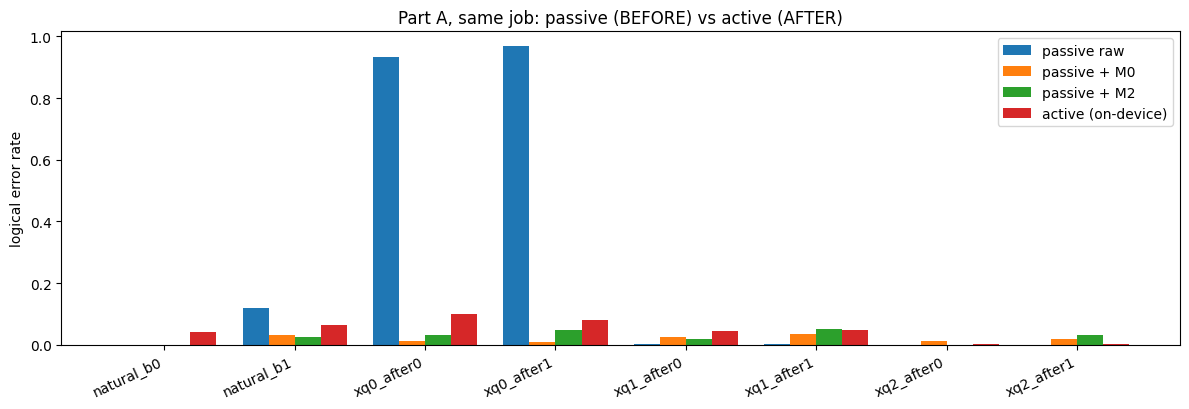

INSIGHTS: Job dbfkb9vpc3tc739nlkeg on ibm_fez returned 4000 aligned shots. Pooled LER: passive raw 0.254, passive+M2 0.026, active 0.048. Active minus passive raw is -0.206 with 95% interval [-0.227, -0.184]; active minus passive+M2 is +0.022 [+0.010, +0.034]. A correction was commanded on 75.5% of active shots. The on-device rule only reacts to the last syndrome, so readout errors and relaxation after that round remain uncorrected.


In [27]:
def parse_partA(result, names, shots):
    recs = []
    for k, nm in enumerate(names):
        cname, ver = nm.split("|")
        d = result[k].data
        syn_bs = [getattr(d, f"syn{r}").get_bitstrings() for r in range(3)]
        fin_bs = d.final.get_bitstrings()
        n = len(fin_bs)
        assert n == shots and all(len(s) == n for s in syn_bs), f"shot count mismatch for {nm}"
        syn = np.zeros((n, 3, 2), int)
        for r in range(3):
            syn[:, r, :] = np.array([bits_from_string(s, 2) for s in syn_bs[r]])
        fin = np.array([bits_from_string(s, 3) for s in fin_bs])
        active = ver == "active"
        det = form_detectors(syn, fin, active=active)
        b = PREP[cname]
        c0, c1 = syn[:, 2, 0], syn[:, 2, 1]
        flips = np.stack([(c0 == 1) & (c1 == 0), (c0 == 1) & (c1 == 1), (c0 == 0) & (c1 == 1)], axis=1).astype(int)
        pre = fin ^ flips if active else fin
        recs.append(pd.DataFrame(dict(config=cname, version=ver, shot=np.arange(n), prepared_bit=b,
            syn=["".join(map(str, syn[i].reshape(-1))) for i in range(n)],
            final=["".join(map(str, fin[i])) for i in range(n)],
            detectors=[tuple(det[i]) for i in range(n)],
            observable_error=(fin[:, 0] != b).astype(int),
            pre_correction_observable=(pre[:, 0] != b).astype(int),
            commanded=(flips.sum(1) > 0).astype(int))))
    return pd.concat(recs, ignore_index=True)

LIVE = None
PARTA = dict(status=HW["status"])
if HW["status"] == "OK" and CAL.get("status") == "OK":
    names = [f"{c}|{v}" for c, v in ORDER]
    try:
        planned = CAL["plan_upper_bound_s"] if CAL.get("plan_upper_bound_s") is not None else CONFIG["qpu_partA_cap_s"]
        job, names_back, recovered = run_or_recover("partA", names, [ISA[k] for k in ORDER], CONFIG["shots_partA"], planned)
        res = job.result()
        assert len(res) == 16 and list(names_back) == names, "result/circuit mapping mismatch"
        sec = job_qpu_seconds(job)
        ledger_append(job_id=job.job_id(), stage="partA", qpu_seconds=sec, status_final="DONE")
        LIVE = parse_partA(res, names, CONFIG["shots_partA"])
        LIVE.to_csv(OUT_DIR / "partA" / f"partA_raw_shots_{job.job_id()}.csv", index=False)
        PARTA = dict(status="OK", job_id=job.job_id(), qpu_seconds=sec, backend=HW["backend"].name, recovered=recovered)
        print("Part A job:", PARTA)
    except RuntimeError as e:
        PARTA = dict(status=str(e).split(":")[0]); print("Part A:", e)
else:
    print("Part A: BLOCKED (", HW["status"], "/ calibration", CAL.get("status"), ") - nothing is faked.")

if LIVE is not None:
    pas = LIVE[LIVE.version == "passive"]; act = LIVE[LIVE.version == "active"]
    Xp = np.array(pas.detectors.tolist(), dtype=np.int8)
    live_pred_p = {"M0": mwpm_predict(m0_matcher_f, Xp), "M1": (m1_f["model"].predict_proba(Xp) >= m1_f["threshold"]).astype(int), "M2": m2_f.predict(Xp).predicted_flip.to_numpy()}
    rows = []
    for c, *_ in PARTA_CONFIGS:
        pc, ac = pas[pas.config == c], act[act.config == c]
        mask = (pas.config == c).to_numpy()
        row = dict(config=c, n_passive=len(pc), passive_raw_LER=pc.observable_error.mean())
        for m in ("M0", "M1", "M2"):
            row[f"passive+{m}_LER"] = float(np.mean(live_pred_p[m][mask] != pc.observable_error.to_numpy()))
        row.update(n_active=len(ac), active_before_feedback_LER=ac.pre_correction_observable.mean(), active_LER=ac.observable_error.mean(), commanded_share=ac.commanded.mean())
        rows.append(row)
    PA_TAB = pd.DataFrame(rows); display(PA_TAB)
    PA_TAB.to_csv(OUT_DIR / "partA_per_configuration.csv", index=False)

    def pooled(label, k, n):
        lo, hi = wilson(k, n); return dict(quantity=label, shots=n, errors=int(k), LER=k / n, wilson_low=lo, wilson_high=hi)
    yp = pas.observable_error.to_numpy()
    pool = [pooled("passive, no decoding (raw)", yp.sum(), len(yp))]
    for m in ("M0", "M1", "M2"):
        pool.append(pooled(f"passive + {m} offline", (live_pred_p[m] != yp).sum(), len(yp)))
    pool.append(pooled("active before feedback (what passive would see)", act.pre_correction_observable.sum(), len(act)))
    pool.append(pooled("active after on-device correction", act.observable_error.sum(), len(act)))
    POOL = pd.DataFrame(pool); display(POOL)
    def diff_ci(k1, n1, k2, n2, B=4000):
        r = np.random.default_rng(SEED + 7)
        d = r.binomial(n1, k1 / n1, B) / n1 - r.binomial(n2, k2 / n2, B) / n2
        return float(k1 / n1 - k2 / n2), ci(d)
    d_act_raw = diff_ci(act.observable_error.sum(), len(act), yp.sum(), len(yp))
    d_act_m2 = diff_ci(act.observable_error.sum(), len(act), (live_pred_p["M2"] != yp).sum(), len(yp))
    print(f"active - passive raw: {d_act_raw[0]:+.3f} [{d_act_raw[1][0]:+.3f}, {d_act_raw[1][1]:+.3f}] | active - passive+M2: {d_act_m2[0]:+.3f} [{d_act_m2[1][0]:+.3f}, {d_act_m2[1][1]:+.3f}]")
    fig, ax = plt.subplots(figsize=(12, 4.2)); x = np.arange(len(PA_TAB)); w = 0.2
    for j, (col, lab) in enumerate([("passive_raw_LER", "passive raw"), ("passive+M0_LER", "passive + M0"), ("passive+M2_LER", "passive + M2"), ("active_LER", "active (on-device)")]):
        ax.bar(x + (j - 1.5) * w, PA_TAB[col], w, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(PA_TAB.config, rotation=25, ha="right"); ax.set_ylabel("logical error rate"); ax.set_title("Part A, same job: passive (BEFORE) vs active (AFTER)"); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / "fig_partA.png", dpi=130); plt.show()
    print("INSIGHTS:", f"Job {PARTA['job_id']} on {PARTA['backend']} returned {len(LIVE)} aligned shots. Pooled LER: passive raw {POOL.LER[0]:.3f}, passive+M2 {POOL.LER[3]:.3f}, active {POOL.LER[5]:.3f}. "
          f"Active minus passive raw is {d_act_raw[0]:+.3f} with 95% interval [{d_act_raw[1][0]:+.3f}, {d_act_raw[1][1]:+.3f}]; active minus passive+M2 is {d_act_m2[0]:+.3f} [{d_act_m2[1][0]:+.3f}, {d_act_m2[1][1]:+.3f}]. "
          f"A correction was commanded on {act.commanded.mean():.1%} of active shots. The on-device rule only reacts to the last syndrome, so readout errors and relaxation after that round remain uncorrected.")

## 17 Frozen models on live Part A shots (optional out-of-time check)

### Score the frozen M0, M1, M2 and controls on the passive shots measured in Part A
**Purpose:** A drift observation: these shots were measured after the training job, with a different fault mix, and are used for evaluation only.

**Inputs:** Passive Part A shots (detectors and measured labels), frozen models reloaded from disk. Status label: `LIVE_OUT_OF_TIME_EVAL`, never used for training or tuning.

**Method:** Same decision rules as the benchmark. Paired bootstrap (2000 resamples) of $\mathrm{LER}_{method}-\mathrm{LER}_{M0}$ on the identical shots.

**Expected output:** LER per method with intervals and paired deltas against M0, plus pattern coverage by the training set.

**Interpretation:** A gap between these numbers and the internal-test numbers mixes drift with a different fault mix (the live set contains a prepared logical 1 and different shots per configuration); it is an observation, not a method ranking.

**Failure mode:** Skipped with a status flag if Part A is blocked.

In [28]:
lk_f = joblib.load(FROZEN_DIR / "lookup.joblib")
LIVE_RESULT = None
if LIVE is None:
    print("Status: BLOCKED / NOT_RUN - Part A has no real shots, so there is nothing to score.")
    print("INSIGHTS: no live shots available; section skipped without fabricating anything.")
else:
    pas = LIVE[LIVE.version == "passive"].reset_index(drop=True)
    Xl = np.array(pas.detectors.tolist(), dtype=np.int8); yl = pas.observable_error.to_numpy()
    preds = {"No-flip control": np.zeros(len(yl), int), "Pattern lookup": lk_f.predict(Xl)[0], "M0 MWPM": live_pred_p["M0"], "M1 MLP": live_pred_p["M1"], "M2 MOR router": live_pred_p["M2"]}
    Bl = np.random.default_rng(SEED + 3).integers(0, len(yl), size=(CONFIG["boot_paired"], len(yl)))
    rows = []
    for k, p in preds.items():
        e = (p != yl).astype(float); lo, hi = ci(boot_metrics(yl, p, Bl[:CONFIG["boot_single"]])["LER"])
        d = (e - (preds["M0 MWPM"] != yl))[Bl].mean(1); dl, dh = ci(d)
        rows.append(dict(method=k, LER=e.mean(), ci_low=lo, ci_high=hi, delta_vs_M0=e.mean() - (preds["M0 MWPM"] != yl).mean(), delta_ci_low=dl, delta_ci_high=dh,
                         verdict="-" if k == "M0 MWPM" else ("NOT_STATISTICALLY_RESOLVABLE" if dl <= 0 <= dh else ("better than M0" if d.mean() < 0 else "worse than M0"))))
    LIVE_RESULT = pd.DataFrame(rows); display(LIVE_RESULT)
    cov_live = float(np.mean([int(p) in seen_tr for p in pat_id(Xl)]))
    print(f"Status LIVE_OUT_OF_TIME_EVAL | {len(yl)} passive shots | pattern coverage by train: {cov_live:.1%}")
    print("INSIGHTS:", "On live passive shots: " + "; ".join(f"{r.method} LER {r.LER:.3f}" for r in LIVE_RESULT.itertuples()) + f". Raw flip rate is {yl.mean():.3f}; "
          f"{int((LIVE_RESULT.verdict == 'NOT_STATISTICALLY_RESOLVABLE').sum())} of 4 comparisons with M0 are not resolvable. {1 - cov_live:.1%} of live shots have patterns never seen in training.")

,method,LER,ci_low,ci_high,delta_vs_M0,delta_ci_low,delta_ci_high,verdict
0,No-flip control,0.2535,0.2340,0.2735,0.2355,0.215,0.2560,worse than M0
1,Pattern lookup,0.0230,0.0165,0.0300,0.0050,-0.002,0.0120,NOT_STATISTICALLY_RESOLVABLE
2,M0 MWPM,0.0180,0.0125,0.0240,0.0000,0.000,0.0000,-
3,M1 MLP,0.0215,0.0150,0.0280,0.0035,-0.004,0.0115,NOT_STATISTICALLY_RESOLVABLE
4,M2 MOR router,0.0260,0.0190,0.0340,0.0080,0.000,0.0160,NOT_STATISTICALLY_RESOLVABLE


Status LIVE_OUT_OF_TIME_EVAL | 2000 passive shots | pattern coverage by train: 98.5%
INSIGHTS: On live passive shots: No-flip control LER 0.254; Pattern lookup LER 0.023; M0 MWPM LER 0.018; M1 MLP LER 0.021; M2 MOR router LER 0.026. Raw flip rate is 0.254; 3 of 4 comparisons with M0 are not resolvable. 1.5% of live shots have patterns never seen in training.


## 18 Job recovery and verification

### Re-query every job ID from IBM and verify it
**Purpose:** Prove that every hardware number in this notebook comes from a completed job on a real device, and that the shot counts match.

**Inputs:** `outputs/qpu_ledger.jsonl` (append-only), `service.job(job_id)`.

**Method:** For each job id: status must be DONE; backend must be in `service.backends(simulator=False)`; number of results must equal the number of circuits; shots returned per circuit must equal shots requested.

**Expected output:** A verification table with one row per job.

**Interpretation:** All rows `OK` makes every Part A and calibration number traceable to a job id.

**Failure mode:** Jobs are re-fetched, never re-run, so this cell costs no QPU time.

In [29]:
REC = pd.DataFrame()
if HW["status"] != "OK" or not ledger_latest():
    print("Status:", HW["status"] if HW["status"] != "OK" else "no jobs in ledger", "- nothing to verify.")
    print("INSIGHTS: no hardware jobs exist in this run, so no hardware number is reported anywhere in the notebook.")
else:
    real_names = {b.name for b in HW["service"].backends(simulator=False)}
    rows = []
    for jid, e in ledger_latest().items():
        job = HW["service"].job(jid)
        st = job.status(); st = str(getattr(st, "name", st))
        res = job.result() if st == "DONE" else None
        try:
            bname = getattr(job.backend(), "name", str(job.backend()))
        except Exception:
            bname = e.get("backend")
        shots_ok = res is not None and len(res) == e["n_circuits"] and all(len(res[i].data.final.get_bitstrings()) == e["shots"] for i in range(len(res)))
        rows.append(dict(stage=e["stage"], job_id=jid, status=st, backend=bname, real_device=bname in real_names, circuits=e["n_circuits"], shots_per_circuit=e["shots"],
                         shots_match=shots_ok, qpu_seconds=e.get("qpu_seconds"), verdict="OK" if (st == "DONE" and bname in real_names and shots_ok) else "CHECK"))
    REC = pd.DataFrame(rows); display(REC)
    print("INSIGHTS:", f"{len(REC)} job(s) re-queried: {int((REC.verdict == 'OK').sum())} verified as completed on a real device with matching shot counts. QPU seconds recorded: "
          + ", ".join(f"{r.stage} {r.qpu_seconds if r.qpu_seconds is not None else 'None (unknown)'}" for r in REC.itertuples()) + ".")

,stage,job_id,status,backend,real_device,circuits,shots_per_circuit,shots_match,qpu_seconds,verdict
0,calibration,dbfka8fgdj9s73bbr170,DONE,ibm_fez,True,4,100,True,2.0,OK
1,partA,dbfkb9vpc3tc739nlkeg,DONE,ibm_fez,True,16,250,True,3.0,OK


INSIGHTS: 2 job(s) re-queried: 2 verified as completed on a real device with matching shot counts. QPU seconds recorded: calibration 2.0, partA 3.0.


## 19 Single-syndrome demo

### One detector vector in, decisions out for every method
**Purpose:** Show the decode path for a single shot and a worked example for each fault class of the internal test, next to its ground truth.

**Inputs:** The 8 detector bits of one shot. The function rejects anything else (DataFrames, dicts, labels, wrong width).

**Method:** Per requested method it returns the predicted flip, a score/probability where the method has one, a status and the measured latency; for M2 also the difficulty class and the decoder used. Stretch quantum methods return `NOT_ATTEMPTED` because they were not run; nothing is simulated.

**Expected output:** A rejection test, then a table with one example per circuit (fault class) of the internal test with ground truth.

**Interpretation:** Ground truth exists only for labelled shots; for a new live shot the same function returns decisions without a truth column.

**Failure mode:** Passing label columns raises an error by design.

In [30]:
def decode_single(detectors, methods=("M0", "M1", "M2")):
    if isinstance(detectors, (dict, pd.Series, pd.DataFrame)):
        reject_label_columns(pd.Series(detectors) if isinstance(detectors, dict) else detectors)
        raise TypeError("Pass the 8 detector bits as a list or array")
    x = np.asarray(detectors)
    if x.shape != (8,):
        raise ValueError(f"Expected exactly 8 detector bits, got shape {x.shape}")
    x = guard_inputs(x[None, :])
    out = {}
    if "M0" in methods:
        t = time.perf_counter_ns(); p = int(mwpm_predict(m0_matcher_f, x)[0])
        out["M0"] = dict(predicted_flip=p, score=None, status="OK", latency_us=(time.perf_counter_ns() - t) / 1e3)
    if "M1" in methods:
        t = time.perf_counter_ns(); pr = float(m1_f["model"].predict_proba(x)[0]); p = int(pr >= m1_f["threshold"])
        out["M1"] = dict(predicted_flip=p, score=pr, status="OK", latency_us=(time.perf_counter_ns() - t) / 1e3)
    if "M2" in methods:
        t = time.perf_counter_ns(); r = m2_f.predict(x).iloc[0]
        out["M2"] = dict(predicted_flip=int(r.predicted_flip), score=None if np.isnan(r.p_cal) else float(r.p_cal), status="OK", difficulty=r.difficulty, decoder=r.decoder,
                         latency_us=(time.perf_counter_ns() - t) / 1e3)
    for s in ("S1", "S2"):
        if s in methods:
            out[s] = dict(predicted_flip=None, score=None, status="NOT_ATTEMPTED (optional stretch, no QPU measurement exists; nothing simulated)")
    return out

for bad in ({"observable_error": 1}, tr.iloc[0], [0, 1, 0], np.zeros(8) + 2):
    try:
        decode_single(bad); raise SystemExit("not rejected")
    except (ValueError, TypeError):
        pass
print("Rejection tests passed (label dict/Series, wrong width, non-binary).")

demo_rows = []
for cname, g in te.sort_values("record_id").groupby("circuit_name"):
    g = g.reset_index(drop=True)
    nz = g[g.detector_event_count > 0]
    r = (nz if len(nz) else g).iloc[0]
    d = list(map(int, np.asarray(r.detectors)))
    out = decode_single(d)
    demo_rows.append(dict(fault_class=cname, record_id=int(r.record_id), detectors="".join(map(str, d)), truth_flip=int(r.observable_error),
                          M0=out["M0"]["predicted_flip"], M1=out["M1"]["predicted_flip"], M1_prob=round(out["M1"]["score"], 3),
                          M2=out["M2"]["predicted_flip"], M2_class=out["M2"]["difficulty"], M2_decoder=out["M2"]["decoder"]))
DEMO = pd.DataFrame(demo_rows); display(DEMO)
print("One full call:", json.dumps(decode_single(list(map(int, X_te[0])), methods=("M0", "M1", "M2", "S1")), default=str, indent=1))
print("INSIGHTS:", f"{len(DEMO)} fault classes shown with ground truth. M0/M1/M2 agree with the truth on {int(((DEMO.M0 == DEMO.truth_flip)).sum())}/{int((DEMO.M1 == DEMO.truth_flip).sum())}/{int((DEMO.M2 == DEMO.truth_flip).sum())} of these {len(DEMO)} examples "
      "(a handful of hand-picked rows is an illustration, not an evaluation). Stretch methods return NOT_ATTEMPTED.")

Rejection tests passed (label dict/Series, wrong width, non-binary).


,fault_class,record_id,detectors,truth_flip,M0,M1,M1_prob,M2,M2_class,M2_decoder
0,rep_d3_r3_b0_passive_natural,118,00001010,0,0,0,0.122,0,EASY,NEURAL
1,rep_d3_r3_b0_passive_xq0_after0,1251,00100000,1,1,1,0.999,1,EASY,NEURAL
2,rep_d3_r3_b0_passive_xq0_after1,3128,00001010,0,0,0,0.122,0,EASY,NEURAL
3,rep_d3_r3_b0_passive_xq1_after0,1882,00110000,0,0,0,0.002,0,EASY,NEURAL
4,rep_d3_r3_b0_passive_xq1_after1,3752,00001100,0,0,0,0.053,0,EASY,NEURAL
5,rep_d3_r3_b0_passive_xq2_after0,2500,00010000,0,0,0,0.010,0,EASY,NEURAL
6,rep_d3_r3_b0_passive_xq2_after1,4376,00000100,0,0,0,0.000,0,EASY,NEURAL
7,rep_d3_r3_b1_passive_natural,627,00000011,0,0,0,0.394,0,EASY,NEURAL


One full call: {
 "M0": {
  "predicted_flip": 1,
  "score": null,
  "status": "OK",
  "latency_us": 109.7
 },
 "M1": {
  "predicted_flip": 1,
  "score": 0.9994653358863874,
  "status": "OK",
  "latency_us": 526.5
 },
 "M2": {
  "predicted_flip": 1,
  "score": 0.9961519141834152,
  "status": "OK",
  "difficulty": "EASY",
  "decoder": "NEURAL",
  "latency_us": 1093.3
 },
 "S1": {
  "predicted_flip": null,
  "score": null,
  "status": "NOT_ATTEMPTED (optional stretch, no QPU measurement exists; nothing simulated)"
 }
}
INSIGHTS: 8 fault classes shown with ground truth. M0/M1/M2 agree with the truth on 8/8/8 of these 8 examples (a handful of hand-picked rows is an illustration, not an evaluation). Stretch methods return NOT_ATTEMPTED.


## 20 Latency and cost

### Per-method and per-stage latency at batch size 1 and at a large batch, plus QPU seconds
**Purpose:** Measure honestly what each decoder costs, and where the router's bookkeeping pays for itself or does not.

**Inputs:** 300 internal-test shots one at a time (batch size 1) and the full 1,000 + 2,000 shots as a batch; the ledger for QPU seconds.

**Method:** Time with `time.perf_counter_ns` after a warm-up. Batch size 1: p50 and p95 over the shots, in microseconds. Large batch: per-shot cost $=T_{batch}/n$, p50/p95 over 15 repeats. M2 stages: S1 difficulty, S2 router lookup, S3 decoder run (identity, cache/MWPM or neural+Platt), S4 output record. This measures **classical decode latency only**; no real-time loop to the QPU is claimed.

**Expected output:** Latency tables (methods and M2 stages), per-class M2 latency, a figure, and the QPU-seconds ledger summary.

**Interpretation:** If M2's total at batch size 1 exceeds that of the plain decoders, the bookkeeping outweighs the saved neural calls at that scale; the printed comparison says which case holds.

**Failure mode:** Timings depend on the laptop and on Python overhead; compare methods with each other, not with real-time hardware budgets.

,method,batch1_p50_us,batch1_p95_us,batch_per_shot_p50_us,batch_per_shot_p95_us
0,Pattern lookup,43.7,88.960,0.330633,0.375990
1,M0 MWPM,30.3,41.890,0.428967,0.765423
2,M1 MLP,116.0,482.115,1.020733,1.255767
3,M2 MOR router,304.3,543.910,1.264133,1.761537


,stage,p50_us,p95_us
0,S1 difficulty,10.4,19.925
1,S2 router lookup,0.3,0.605
2,S3 decoder run,111.6,202.620
3,S4 output record,0.2,0.300
4,total,122.3,226.210


,shots,p50_us,p95_us
class,,,
EASY,217,123.1,233.760
HARD,27,127.1,222.770
TRIVIAL,56,11.2,16.175


,stage,per_shot_us
0,S1 difficulty (all shots),0.039350
1,S3 MWPM/cache on routed shots,0.013750
2,S3 neural+Platt on routed shots,0.834283
3,M2 total,1.264133


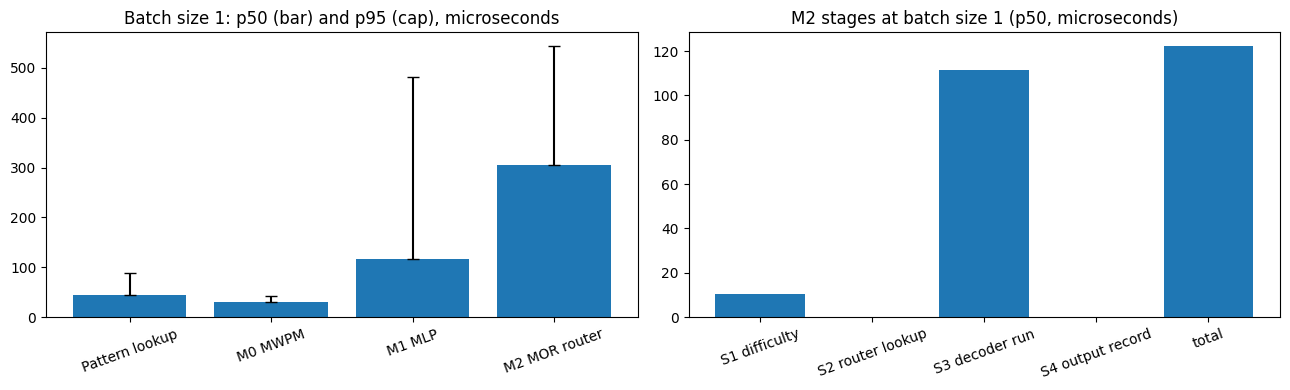

,stage,job_id,backend,n_circuits,shots,qpu_seconds
0,calibration,dbfka8fgdj9s73bbr170,ibm_fez,4,100,2.0
1,partA,dbfkb9vpc3tc739nlkeg,ibm_fez,16,250,3.0


INSIGHTS: At batch size 1 the p50 latency is Pattern lookup 44 us, M0 MWPM 30 us, M1 MLP 116 us, M2 MOR router 304 us. M2 is slower than the plain MLP at batch size 1 (total p50 304 us vs 116 us); its S1 difficulty step alone costs 10.4 us p50. In large batches the per-shot cost is Pattern lookup 0.3 us, M0 MWPM 0.4 us, M1 MLP 1.0 us, M2 MOR router 1.3 us. QPU seconds used so far: 5.0.


In [31]:
def pct(a, q): return float(np.percentile(a, q))
def time_calls(fn, items, warm=20):
    for it in items[:warm]:
        fn(it)
    ts = []
    for it in items:
        t = time.perf_counter_ns(); fn(it); ts.append(time.perf_counter_ns() - t)
    return np.array(ts) / 1e3

def m2_staged(x, T):
    t0 = time.perf_counter_ns(); cls = difficulty_of(x)[0]
    t1 = time.perf_counter_ns(); dec = m2_f.routing[cls]
    t2 = time.perf_counter_ns(); pred, p = 0, np.nan
    if dec == "MWPM":
        pred = int(m2_f.mwpm(x)[0])
    elif dec == "NEURAL":
        p = float(m2_f.calibrate(m2_f.mlp.predict_proba(x))[0]); pred = int(p >= m2_f.thr)
    t3 = time.perf_counter_ns(); rec = (pred, cls, dec, p)
    t4 = time.perf_counter_ns()
    T["S1 difficulty"].append(t1 - t0); T["S2 router lookup"].append(t2 - t1); T["S3 decoder run"].append(t3 - t2); T["S4 output record"].append(t4 - t3); T["total"].append(t4 - t0); T["class"].append(cls)
    return rec

n1 = CONFIG["latency_single_shots"]
singles = [X_te[i:i + 1] for i in range(n1)]
fns = {"Pattern lookup": lambda x: lk_f.predict(x), "M0 MWPM": lambda x: mwpm_predict(m0_matcher_f, x),
       "M1 MLP": lambda x: m1_f["model"].predict_proba(x) >= m1_f["threshold"], "M2 MOR router": lambda x: m2_f.predict(x)}
lat1 = {k: time_calls(f, singles) for k, f in fns.items()}
T = {k: [] for k in ["S1 difficulty", "S2 router lookup", "S3 decoder run", "S4 output record", "total", "class"]}
for x in singles[:20]:
    m2_staged(x, {k: [] for k in T})
for x in singles:
    m2_staged(x, T)
stage_df = pd.DataFrame({k: np.array(v) / 1e3 for k, v in T.items() if k != "class"})
stage_tab = pd.DataFrame([dict(stage=k, p50_us=pct(stage_df[k], 50), p95_us=pct(stage_df[k], 95)) for k in stage_df.columns])
by_class = pd.DataFrame({"class": T["class"], "total_us": stage_df["total"]}).groupby("class").total_us.agg(shots="size", p50_us=lambda a: pct(a, 50), p95_us=lambda a: pct(a, 95))

Xbig = np.vstack([X_te, X_fi])
latB = {}
for k, f in {"Pattern lookup": lambda X: lk_f.predict(X), "M0 MWPM": lambda X: mwpm_predict(m0_matcher_f, X),
             "M1 MLP": lambda X: m1_f["model"].predict_proba(X) >= m1_f["threshold"], "M2 MOR router": lambda X: m2_f.predict(X)}.items():
    f(Xbig)
    ts = []
    for _ in range(CONFIG["latency_batch_repeats"]):
        t = time.perf_counter_ns(); f(Xbig); ts.append((time.perf_counter_ns() - t) / 1e3 / len(Xbig))
    latB[k] = np.array(ts)
LAT = pd.DataFrame([dict(method=k, batch1_p50_us=pct(lat1[k], 50), batch1_p95_us=pct(lat1[k], 95), batch_per_shot_p50_us=pct(latB[k], 50), batch_per_shot_p95_us=pct(latB[k], 95)) for k in fns])
display(LAT); display(stage_tab); display(by_class)

# batch-level M2 stage costs
cls_big = difficulty_of(Xbig); dec_big = np.array([m2_f.routing[c] for c in cls_big], dtype=object)
def tstage(fn, reps=10):
    ts = []
    for _ in range(reps):
        t = time.perf_counter_ns(); fn(); ts.append(time.perf_counter_ns() - t)
    return np.median(ts) / 1e3 / len(Xbig)
stage_batch = pd.DataFrame([dict(stage="S1 difficulty (all shots)", per_shot_us=tstage(lambda: difficulty_of(Xbig))),
                            dict(stage="S3 MWPM/cache on routed shots", per_shot_us=tstage(lambda: m2_f.mwpm(Xbig[dec_big == "MWPM"]) if (dec_big == "MWPM").any() else None)),
                            dict(stage="S3 neural+Platt on routed shots", per_shot_us=tstage(lambda: m2_f.calibrate(m2_f.mlp.predict_proba(Xbig[dec_big == "NEURAL"])) if (dec_big == "NEURAL").any() else None)),
                            dict(stage="M2 total", per_shot_us=pct(latB["M2 MOR router"], 50))])
display(stage_batch)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(LAT.method, LAT.batch1_p50_us, yerr=[np.zeros(len(LAT)), LAT.batch1_p95_us - LAT.batch1_p50_us], capsize=4); ax[0].set_title("Batch size 1: p50 (bar) and p95 (cap), microseconds"); ax[0].tick_params(axis="x", rotation=20)
ax[1].bar(stage_tab.stage, stage_tab.p50_us); ax[1].set_title("M2 stages at batch size 1 (p50, microseconds)"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_latency.png", dpi=130); plt.show()

led = pd.DataFrame(list(ledger_latest().values())) if ledger_latest() else pd.DataFrame()
if len(led):
    display(led[["stage", "job_id", "backend", "n_circuits", "shots", "qpu_seconds"]])
QPU_TOTAL = None if (not len(led) or led.qpu_seconds.isna().all()) else float(led.qpu_seconds.dropna().sum())
l1 = LAT.set_index("method")
faster = "slower than" if l1.loc["M2 MOR router", "batch1_p50_us"] > l1.loc["M1 MLP", "batch1_p50_us"] else "faster than"
print("INSIGHTS:", f"At batch size 1 the p50 latency is " + ", ".join(f"{k} {v:.0f} us" for k, v in l1.batch1_p50_us.items()) + ". "
      f"M2 is {faster} the plain MLP at batch size 1 (total p50 {l1.loc['M2 MOR router', 'batch1_p50_us']:.0f} us vs {l1.loc['M1 MLP', 'batch1_p50_us']:.0f} us); "
      f"its S1 difficulty step alone costs {stage_tab.set_index('stage').loc['S1 difficulty', 'p50_us']:.1f} us p50. In large batches the per-shot cost is " + ", ".join(f"{k} {v:.1f} us" for k, v in l1.batch_per_shot_p50_us.items()) + ". "
      + (f"QPU seconds used so far: {QPU_TOTAL:.1f}." if QPU_TOTAL is not None else "QPU seconds: no completed hardware job reports usage (None, not 0)."))

## 21 Findings

### Chosen method, claims, negative results, threats to validity
**Purpose:** State which decoder to use and why, using only numbers printed above and the selection rule fixed in section 10.

**Inputs:** `LER_TE`, `PAIRED`, `LAT`, `POOL`/`PARTA` (if available), `uns`.

**Method:** Rule: lowest internal-test LER among M0, M1, M2; methods whose paired interval against the best contains zero form a tie group; within a tie group choose the lowest batch-1 p50 latency. If the best method is not resolvably better than the pattern-lookup control the result is called inconclusive and the winner is only exploratory.

**Expected output:** A findings text saved to `outputs/findings.txt`.

**Interpretation:** Every claim carries a number; negative and unresolved results are stated as such.

**Failure mode:** If the paired intervals include zero for all comparisons, the honest conclusion is that the methods cannot be separated with 1,000 test shots.

In [32]:
cands = ["M0 MWPM", "M1 MLP", "M2 MOR router"]
best = min(cands, key=lambda k: LER_TE[k])
tied = [m for m in cands if m != best and paired(best, m)["verdict"] == "NOT_STATISTICALLY_RESOLVABLE"]
group = [best] + tied
choice = min(group, key=lambda k: l1.loc[k, "batch1_p50_us"])
vs_lookup = paired(best, "Pattern lookup"); vs_noflip = paired(best, "No-flip control")
inconclusive = vs_lookup["verdict"] == "NOT_STATISTICALLY_RESOLVABLE"
lines = []
lines.append(f"1. Decoding versus no decoding: best LER {LER_TE[best]:.3f} ({best}) against raw LER {LER_TE['No-flip control']:.3f}; paired delta vs no-flip {vs_noflip['delta_LER']:+.3f} [{vs_noflip['ci_low']:+.3f}, {vs_noflip['ci_high']:+.3f}] ({vs_noflip['verdict']}).")
lines.append("2. LER of every method on the internal test: " + "; ".join(f"{k} {v:.3f}" for k, v in LER_TE.items()) + ".")
lines.append(f"3. Best vs pattern-lookup control: delta {vs_lookup['delta_LER']:+.3f} [{vs_lookup['ci_low']:+.3f}, {vs_lookup['ci_high']:+.3f}] -> {vs_lookup['verdict']}." + (" The comparison with the strongest control is INCONCLUSIVE; the winner below is exploratory." if inconclusive else ""))
lines.append(f"4. Tie group by paired interval with {best}: {tied if tied else 'none (best method is resolvably ahead of M0/M1/M2)'}; by the latency tie-break the recommended decoder is {choice} (batch-1 p50 {l1.loc[choice, 'batch1_p50_us']:.0f} us).")
r_ = PAIRED[(PAIRED.A == "M2 MOR router") & (PAIRED.B == "M1 MLP")].iloc[0]; r0 = PAIRED[(PAIRED.A == "M2 MOR router") & (PAIRED.B == "M0 MWPM")].iloc[0]
lines.append(f"5. Router: M2 vs M1 delta {r_.delta_LER:+.3f} ({r_.verdict}); M2 vs M0 delta {r0.delta_LER:+.3f} ({r0.verdict}). It avoided the neural network on {no_nn_share:.1%} of internal-test shots, "
             f"but at batch size 1 it is {faster} the plain MLP ({l1.loc['M2 MOR router', 'batch1_p50_us']:.0f} vs {l1.loc['M1 MLP', 'batch1_p50_us']:.0f} us).")
lines.append(f"6. Calibration: ECE on test {ECE_TE['M1 raw']:.3f} (M1 raw), {ECE_TE['M2 raw']:.3f} (M2 MLP raw), {ECE_TE['M2 Platt']:.3f} (M2 after Platt).")
lines.append(f"7. Unseen patterns: {int((~seen_te).sum())} internal-test shots ({(~seen_te).mean():.1%}) had patterns not in train; the final test has {1 - cov(P_fi):.1%} (drift observation, no labels).")
if LIVE is not None:
    lines.append(f"8. Part A (job {PARTA['job_id']}, {PARTA['backend']}): pooled LER passive raw {POOL.LER[0]:.3f}; passive+M2 {POOL.LER[3]:.3f}; active on-device {POOL.LER[5]:.3f}; active minus passive raw {d_act_raw[0]:+.3f} [{d_act_raw[1][0]:+.3f}, {d_act_raw[1][1]:+.3f}], active minus passive+M2 {d_act_m2[0]:+.3f} [{d_act_m2[1][0]:+.3f}, {d_act_m2[1][1]:+.3f}].")
else:
    lines.append(f"8. Part A: {PARTA['status']} - no hardware claim is made.")
lines.append("9. Stretch methods S1 and S2: NOT_ATTEMPTED. No quantum-advantage claim is made or supported.")
threats = ["Most labelled shots carry a deliberately injected X, so the fault mix is not natural noise.",
           "Train and internal test come from one job; the final test is a later job (drift), and has no labels here.",
           "Only bit-flip errors and a distance-3 code: this is a research prototype, not fault tolerance.",
           f"Only {len(set(P_tr))} distinct input patterns exist, so a lookup table is nearly as expressive as any model; differences of a few shots are noise at n={N_TE}.",
           "Part A uses 250 shots per circuit; per-configuration intervals are wide and the active-vs-passive comparison is inside one job only.",
           "Latency is classical Python latency on a laptop, not a real-time control-system claim."]
FINDINGS = "FINDINGS\n" + "\n".join(lines) + "\n\nTHREATS TO VALIDITY\n" + "\n".join("- " + t for t in threats)
(OUT_DIR / "findings.txt").write_text(FINDINGS)
print(FINDINGS)
print("\nINSIGHTS:", f"Recommended decoder: {choice}" + (" (exploratory, comparison with the lookup control is inconclusive)" if inconclusive else "") + f". Findings saved to outputs/findings.txt.")

FINDINGS
1. Decoding versus no decoding: best LER 0.018 (M1 MLP) against raw LER 0.245; paired delta vs no-flip -0.227 [-0.253, -0.200] (A better (lower LER)).
2. LER of every method on the internal test: No-flip control 0.245; Pattern lookup 0.020; M0 MWPM 0.028; M1 MLP 0.018; M2 MOR router 0.020.
3. Best vs pattern-lookup control: delta -0.002 [-0.005, +0.000] -> NOT_STATISTICALLY_RESOLVABLE. The comparison with the strongest control is INCONCLUSIVE; the winner below is exploratory.
4. Tie group by paired interval with M1 MLP: ['M0 MWPM', 'M2 MOR router']; by the latency tie-break the recommended decoder is M0 MWPM (batch-1 p50 30 us).
5. Router: M2 vs M1 delta +0.002 (NOT_STATISTICALLY_RESOLVABLE); M2 vs M0 delta -0.008 (NOT_STATISTICALLY_RESOLVABLE). It avoided the neural network on 20.2% of internal-test shots, but at batch size 1 it is slower than the plain MLP (304 vs 116 us).
6. Calibration: ECE on test 0.024 (M1 raw), 0.032 (M2 MLP raw), 0.016 (M2 after Platt).
7. Unseen patte

## 22 Scorecard against the judging standards

### End-goal comparison table and the eight judging standards with evidence
**Purpose:** Summarise accuracy, cost, latency and risk for all methods, and tick every judging standard against a section of this notebook with an automatic check where possible.

**Inputs:** All results above, the files in `outputs/`, the saved notebook on disk.

**Method:** Automatic checks: hashes verified, freeze manifest earlier than the prediction files, simulator scan, six-field Markdown above every code cell (read from the saved notebook), job verification.

**Expected output:** The end-goal table, a chart, and the scorecard.

**Interpretation:** A `CHECK` entry says exactly what to fix before opening the pull request.

**Failure mode:** The six-field check reads the notebook from disk, so save the notebook once before the final run to get a meaningful answer.

,method,LER,accuracy,batch1_p50_us,neural_calls_share,main_risk
0,No-flip control,0.245,0.755,NaN,0.000,decodes nothing (baseline)
1,Pattern lookup,0.020,0.980,43.7,0.000,"unseen patterns default to 0 (0.5% of test, 0...."
2,M0 MWPM,0.028,0.972,30.3,0.000,model of noise is generic; cannot see flips in...
3,M1 MLP,0.018,0.982,116.0,1.000,can only learn what the training patterns show...
4,M2 MOR router,0.020,0.980,304.3,0.798,routing table is fitted on a small routing sli...


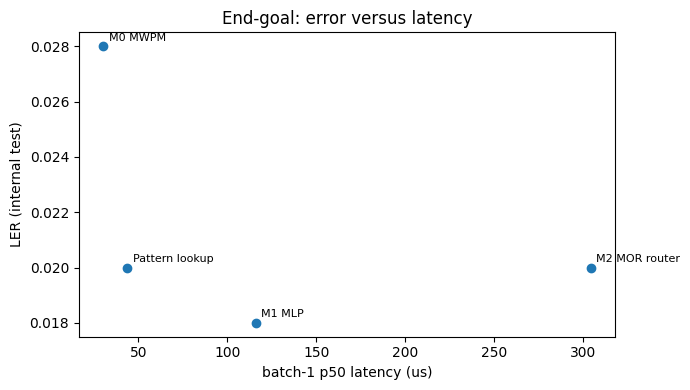

,#,standard,evidence,status
0,1,Clear problem statement and scope,Section 00 cover,OK
1,2,Clear outcome and deliverables,"Sections 12, 19, 21; CSVs in outputs/",OK
2,3,Leakage-safe data use,"Sections 02, 03, 05, 09, 11, 12 (hashes, guard...",OK
3,4,Methodology comparison,"Sections 07 to 10 (identical shots, intervals,...",OK
4,5,Real-hardware circuits BEFORE/AFTER within budget,"Sections 13 to 16, 18",OK
5,6,Technical explanation and insights,Six-field Markdown above every code cell; INSI...,CHECK: 6 of 32 code cells lack the six fields
6,7,Final comparison and end goals,Sections 20 to 22,OK
7,8,Integrity and reproducibility,"Sections 01, 18, 23 (simulator scan, secret sc...",OK
8,Bonus,"Optional quantum stretch (S1, S2)",NOT_ATTEMPTED,NOT_ATTEMPTED


INSIGHTS: 7 of 8 standards show OK automatically; the rest say what is missing. Best LER 0.018 versus raw 0.245.


In [33]:
goal = pd.DataFrame([
    dict(method="No-flip control", LER=LER_TE["No-flip control"], accuracy=1 - LER_TE["No-flip control"], batch1_p50_us=np.nan, neural_calls_share=0.0, main_risk="decodes nothing (baseline)"),
    dict(method="Pattern lookup", LER=LER_TE["Pattern lookup"], accuracy=1 - LER_TE["Pattern lookup"], batch1_p50_us=l1.loc["Pattern lookup", "batch1_p50_us"], neural_calls_share=0.0, main_risk=f"unseen patterns default to 0 ({(~seen_te).mean():.1%} of test, {1 - cov(P_fi):.1%} of final test)"),
    dict(method="M0 MWPM", LER=LER_TE["M0 MWPM"], accuracy=1 - LER_TE["M0 MWPM"], batch1_p50_us=l1.loc["M0 MWPM", "batch1_p50_us"], neural_calls_share=0.0, main_risk="model of noise is generic; cannot see flips invisible to detectors"),
    dict(method="M1 MLP", LER=LER_TE["M1 MLP"], accuracy=1 - LER_TE["M1 MLP"], batch1_p50_us=l1.loc["M1 MLP", "batch1_p50_us"], neural_calls_share=1.0, main_risk="can only learn what the training patterns show; drift"),
    dict(method="M2 MOR router", LER=LER_TE["M2 MOR router"], accuracy=1 - LER_TE["M2 MOR router"], batch1_p50_us=l1.loc["M2 MOR router", "batch1_p50_us"], neural_calls_share=1 - no_nn_share, main_risk="routing table is fitted on a small routing slice; extra bookkeeping"),
])
display(goal)
fig, ax = plt.subplots(figsize=(7, 4)); ax.scatter(goal.batch1_p50_us, goal.LER)
for r in goal.itertuples():
    ax.annotate(r.method, (r.batch1_p50_us if not np.isnan(r.batch1_p50_us) else 0, r.LER), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("batch-1 p50 latency (us)"); ax.set_ylabel("LER (internal test)"); ax.set_title("End-goal: error versus latency"); plt.tight_layout(); plt.savefig(FIG_DIR / "fig_endgoal.png", dpi=130); plt.show()

# automatic checks
def six_field_ok():
    p = SRC_DIR / "main.ipynb"
    if not p.exists():
        return None
    nb = nbformat.read(p, as_version=4); bad = 0; total = 0
    for i, c in enumerate(nb.cells):
        if c.cell_type == "code" and c.source.strip():
            total += 1
            prev = nb.cells[i - 1] if i else None
            if not (prev is not None and prev.cell_type == "markdown" and all(f in prev.source for f in ("**Purpose:**", "**Inputs:**", "**Method:**", "**Expected output:**", "**Interpretation:**", "**Failure mode:**"))):
                bad += 1
    return (total, bad)
sf = six_field_ok()
man_t = dt.datetime.fromisoformat(man["frozen_at_utc"]).timestamp()
pred_files = [OUT_DIR / f"predictions_final_test_M{i}.csv" for i in range(3)]
freeze_ok = all(f.exists() and f.stat().st_mtime >= man_t for f in pred_files)
hw_ok = (PARTA.get("status") == "OK") and (len(REC) > 0 and (REC.verdict == "OK").all())
score = pd.DataFrame([
    (1, "Clear problem statement and scope", "Section 00 cover", "OK"),
    (2, "Clear outcome and deliverables", "Sections 12, 19, 21; CSVs in outputs/", "OK" if all(f.exists() for f in pred_files) else "CHECK"),
    (3, "Leakage-safe data use", "Sections 02, 03, 05, 09, 11, 12 (hashes, guard, disjoint slices, freeze before predictions)", "OK" if (integrity.status == "OK").all() and freeze_ok else "CHECK"),
    (4, "Methodology comparison", "Sections 07 to 10 (identical shots, intervals, paired deltas, selection rule)", "OK"),
    (5, "Real-hardware circuits BEFORE/AFTER within budget", "Sections 13 to 16, 18", "OK" if hw_ok else f"{PARTA.get('status', 'BLOCKED')} - fix access and re-run"),
    (6, "Technical explanation and insights", "Six-field Markdown above every code cell; INSIGHTS printed from numbers", ("unknown (save the notebook first)" if sf is None else ("OK" if sf[1] == 0 else f"CHECK: {sf[1]} of {sf[0]} code cells lack the six fields"))),
    (7, "Final comparison and end goals", "Sections 20 to 22", "OK"),
    (8, "Integrity and reproducibility", "Sections 01, 18, 23 (simulator scan, secret scan, job verification)", "OK" if SIM_SCAN_PASS else "CHECK"),
    ("Bonus", "Optional quantum stretch (S1, S2)", "NOT_ATTEMPTED", "NOT_ATTEMPTED"),
], columns=["#", "standard", "evidence", "status"])
display(score)
print("INSIGHTS:", f"{int((score.status == 'OK').sum())} of 8 standards show OK automatically; the rest say what is missing. Best LER {goal.set_index('method').LER.drop('No-flip control').min():.3f} versus raw {LER_TE['No-flip control']:.3f}.")

## 23 Secret scan and evidence index

### Confirm that no credential is in the submission folder and index every evidence file
**Purpose:** Make sure no API key, token or CRN is stored in any file you would upload, and list all evidence with hashes.

**Inputs:** All text files under the submission folder (the parent of `src/`), the repository `.gitignore`, the credential values of this session.

**Method:** Search for the literal secret values, the prefix `crn:v1:`, and assignments such as `QISKIT_IBM_TOKEN = '...'`. A `.env` file inside the submission folder is flagged as a warning because it must never be committed.

**Expected output:** PASS/FAIL for the secret scan and `outputs/evidence_index.json`.

**Interpretation:** PASS means the folder can be committed; the notebook only ever read the secrets from the environment.

**Failure mode:** Re-run this cell after saving the executed notebook, because outputs are written to disk only when you save.

In [35]:

import json
from pathlib import Path
from IPython.display import display

# 1. Remove the usage snapshot containing the instance CRN.
record_path = OUT_DIR / "backend_record.json"

if record_path.exists():
    record = json.loads(record_path.read_text(encoding="utf-8"))
    record.pop("usage_snapshot", None)
    record_path.write_text(json.dumps(record, indent=2, default=str))
    print("Removed usage snapshot from backend_record.json")

# 2. Clear outputs from the saved notebook.
# This requires nbformat, which is commonly installed with Jupyter.
import nbformat

for notebook_path in SUB_DIR.rglob("*.ipynb"):
    if ".ipynb_checkpoints" in notebook_path.parts:
        continue

    try:
        nb = nbformat.read(notebook_path, as_version=4)
        for cell in nb.cells:
            if cell.cell_type == "code":
                cell.outputs = []
                cell.execution_count = None
        nbformat.write(nb, notebook_path)
        print("Cleared saved outputs:", notebook_path.name)
    except Exception:
        print("Could not update a notebook file.")

# 3. Rerun the existing secret scan.
hits = []
for p in SUB_DIR.rglob("*"):
    if not p.is_file() or ".ipynb_checkpoints" in p.parts:
        continue
    if p.name == ".env" or p.suffix == ".env":
        continue
    if p.suffix.lower() not in text_suffix or p.stat().st_size > 50_000_000:
        continue

    try:
        txt = p.read_text(errors="ignore")
    except Exception:
        continue

    # Check for the actual token, not the instance CRN.
    token = os.environ.get("QISKIT_IBM_TOKEN", "")
    if token and len(token) >= 12 and token in txt:
        hits.append(str(p.relative_to(REPO_ROOT)))

SECRET_SCAN_PASS = len(hits) == 0
print("API token scan:", "PASS" if SECRET_SCAN_PASS else "FAIL")
if hits:
    print("Files containing the token:", hits)


Removed usage snapshot from backend_record.json
Cleared saved outputs: main.ipynb
API token scan: PASS


In [36]:
SUB_DIR = SRC_DIR.parent
text_suffix = {".py", ".ipynb", ".md", ".json", ".jsonl", ".csv", ".txt", ".toml", ".yml", ".yaml", ".cfg", ".qasm"}
hits, env_files = [], []
patterns = [re.compile(r"crn:v1:[A-Za-z0-9:\-]+"), re.compile(r"QISKIT_IBM_TOKEN\s*[=:]\s*['\"]?[A-Za-z0-9_\-]{20,}")]
for p in SUB_DIR.rglob("*"):
    if not p.is_file() or ".ipynb_checkpoints" in p.parts:
        continue
    if p.name == ".env" or p.suffix == ".env":
        env_files.append(str(p.relative_to(REPO_ROOT))); continue
    if p.suffix.lower() not in text_suffix or p.stat().st_size > 50_000_000:
        continue
    try:
        txt = p.read_text(errors="ignore")
    except Exception:
        continue
    for s in SECRET_VALUES:
        if len(s) >= 12 and s in txt:
            hits.append((str(p.relative_to(REPO_ROOT)), "literal secret value"))
    for pat in patterns:
        if pat.search(txt):
            hits.append((str(p.relative_to(REPO_ROOT)), pat.pattern[:20]))
SECRET_SCAN_PASS = len(hits) == 0
print("SECRET SCAN:", "PASS" if SECRET_SCAN_PASS else f"FAIL {hits}")
if env_files:
    print("WARNING: .env file(s) inside the submission folder (keep them git-ignored):", env_files)
print(".gitignore ignores .env:", env_ignored)
scanned2, scan_df2 = scan_sources()
print("Simulator scan on the saved notebook:", "PASS" if scan_df2.hits.sum() == 0 else "FAIL")

ev = {}
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        ev[str(p.relative_to(OUT_DIR))] = dict(bytes=p.stat().st_size, sha256=sha256_file(p)[:16])
index = dict(generated_utc=dt.datetime.now(dt.timezone.utc).isoformat(), job_ids={e["stage"]: j for j, e in ledger_latest().items()}, files=ev,
             qpu_seconds_total=QPU_TOTAL, status=dict(hardware=HW["status"], partA=PARTA.get("status"), stretch="NOT_ATTEMPTED"))
(OUT_DIR / "evidence_index.json").write_text(json.dumps(index, indent=2, default=str))
print(f"{len(ev)} evidence files indexed in outputs/evidence_index.json")
print("INSIGHTS:", f"Secret scan {'passed' if SECRET_SCAN_PASS else 'FAILED'} over the submission folder; {len(ev)} evidence files hashed; job ids: {index['job_ids'] or 'none'}.")
assert SECRET_SCAN_PASS, "Remove the leaked secret before committing and rotate the key in IBM Cloud."

SECRET SCAN: PASS
.gitignore ignores .env: True
Simulator scan on the saved notebook: PASS
34 evidence files indexed in outputs/evidence_index.json
INSIGHTS: Secret scan passed over the submission folder; 34 evidence files hashed; job ids: {'calibration': 'dbfka8fgdj9s73bbr170', 'partA': 'dbfkb9vpc3tc739nlkeg'}.


---
## Appendix: how this notebook meets the Q-DecodeQEC deliverables

The prediction files `predictions_final_test_M0.csv`, `predictions_final_test_M1.csv`, `predictions_final_test_M2.csv` are in `outputs/`. Evidence (job IDs, raw per-shot records, QPY files, circuit metrics, figures, ledger, manifests) is in `outputs/`. The stretch methods S1 and S2 were deliberately not attempted. Cite the IBM Quantum Platform and the organisers' dataset in the report.